# Forecasting sector volatility with GARCH and GARCH-MIDAS

This notebook implements and evaluates monthly realised-variance forecasts from GARCH(1,1) and GARCH-MIDAS.
It is designed to be fully reproducible: all modelling choices, validation checks and forecast evaluations are reported alongside the implementation.

**Roadmap.** Steps 0–12 build and score the main comparison: GARCH against GARCH-MIDAS with
the credit spread, refitted every month, exactly aligned with the Elastic Net. Step 13
reports a yearly-refit robustness exercise. Step 14 examines the sources of the GARCH-MIDAS
forecast errors. Step 15 relates these results to the Elastic Net and XGBoost specifications,
and Step 16 records the final validation checks.

## The question

**Does a macroeconomic credit-risk measure improve one-month-ahead forecasts of sector volatility?**

We study five US sector funds (ETFs): XLI (industrials), XLB (materials), XLE (energy),
XLY (consumer discretionary) and XLF (financials).

## The two models we compare

1. **GARCH(1,1)** models conditional daily variance using an ETF's own return history and
   provides the persistence-only benchmark.
2. **GARCH-MIDAS** augments the short-run GARCH component with a macro-driven long-run
   variance component. The primary specification uses **BAA10Y**, the corporate default-risk
   premium relative to the 10-year Treasury yield.

GARCH is nested within GARCH-MIDAS: setting the credit-spread coefficient to zero yields the
GARCH specification. The comparison therefore isolates the incremental contribution of BAA10Y.

## Why the credit spread?

BAA10Y measures the **default-risk premium**, a macro-financial variable identified by
Chen, Roll and Ross (1986) as relevant to equity-market risk. A wider spread indicates
greater credit risk and financial stress; the corresponding testable prediction is a positive
association with future sector volatility. BAA10Y is also market-based and is not subject to
historical revision.

## Step 0: Settings

The following parameters define the forecasting protocol. They are aligned with the Elastic
Net notebook to ensure common samples, targets and forecast origins:

* **Excess returns:** daily ETF returns less the risk-free rate.
* **Burn-in:** 60 monthly observations before the initial forecast.
* **Estimation window:** expanding, with re-estimation at every monthly forecast origin.
* **Forecast horizon:** one month ahead.

In [1]:
import os, json, time, hashlib, warnings
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import norm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)

PROJECT_ROOT = "."
PRICE_PATH = os.path.join(PROJECT_ROOT, "daily_returns_panel_ver2.csv")
MACRO_PATH = os.path.join(PROJECT_ROOT, "final_macro_data.csv")
# Read ONLY to check that our forecast rows line up with the EN forecasts. Never a model input.
EN_TIDY_PATH = os.path.join(PROJECT_ROOT, "en_forecasts_expanding_tidy.csv")
OUT_TIDY = os.path.join(PROJECT_ROOT, "garch_forecasts_expanding_tidy.csv")
OUT_DETAIL = os.path.join(PROJECT_ROOT, "garch_forecasts_expanding_detail.csv")
CACHE_DIR = os.path.join(PROJECT_ROOT, "cache_gm_phase2")
os.makedirs(CACHE_DIR, exist_ok=True)

TICKERS = ["XLI", "XLB", "XLE", "XLY", "XLF"]   # same order as the EN notebook

# ---- protocol: every setting matches elastic_net_phase2.ipynb ----
SAMPLE_START = "2003-02"   # Jan 2003 holds a single session in the panel; EN drops it too
BURN_IN = 60               # estimation months before the first forecast
REFIT_EVERY = 1            # re-estimate every month, expanding window
HORIZON = 1                # one month ahead
K_MIDAS = 1                # one lagged month of macro data in tau
N_STARTS = 3               # fixed starting points for the pooled optimiser
N_RANDOM = 10              # extra random starting points (seeded by the origin month)
DRIVER = "BAA10Y"          # credit spread: Moody's BAA corporate yield minus the 10-year Treasury yield
MIDAS_LABEL = "garch_midas_" + DRIVER.lower()
MODELS = {"garch": None, MIDAS_LABEL: DRIVER}   # label -> macro driver (None = GARCH)
CACHE_ENABLED = True       # switched off inside the leakage audit


def _md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


# The cache key includes a fingerprint of both input files, so any change to the data
# invalidates every cached refit instead of silently replaying stale parameters.
DATA_FINGERPRINT = _md5(PRICE_PATH)[:12] + "_" + _md5(MACRO_PATH)[:12]

print("GARCH / GARCH-MIDAS  |  Phase 2  |  build: garchmidas_phase2")
print("=" * 80)
print(f"returns file    : {os.path.basename(PRICE_PATH)}  (excess returns, xret_*)")
print(f"macro file      : {os.path.basename(MACRO_PATH)}  (driver: {DRIVER})")
print(f"models          : {list(MODELS)}")
print(f"tickers         : {TICKERS}")
print(f"sample start    : {SAMPLE_START}  (January 2003 dropped)")
print(f"burn-in / refit : {BURN_IN} months / every {REFIT_EVERY} month, expanding window")
print(f"horizon / K     : h = {HORIZON} month / K = {K_MIDAS}")
print(f"starting points : {N_STARTS} fixed + {N_RANDOM} random + last month's answer (+ GARCH answer for GARCH-MIDAS)")
print(f"data fingerprint: {DATA_FINGERPRINT}")

GARCH / GARCH-MIDAS  |  Phase 2  |  build: garchmidas_phase2
returns file    : daily_returns_panel_ver2.csv  (excess returns, xret_*)
macro file      : final_macro_data (1).csv  (driver: BAA10Y)
models          : ['garch', 'garch_midas_baa10y']
tickers         : ['XLI', 'XLB', 'XLE', 'XLY', 'XLF']
sample start    : 2003-02  (January 2003 dropped)
burn-in / refit : 60 months / every 1 month, expanding window
horizon / K     : h = 1 month / K = 1
starting points : 3 fixed + 10 random + last month's answer (+ GARCH answer for GARCH-MIDAS)
data fingerprint: 2c571703b96e_1461f053f855


## Step 1: Load the data

The analysis uses two input files:

* `daily_returns_panel_ver2.csv` — daily returns for each ETF;
* `final_macro_data.csv` — monthly macroeconomic data, from which the primary specification uses `BAA10Y`.

The forecast target is monthly **realised variance (RV)**, defined as the sum of squared daily
excess returns within the month. The models forecast RV for the subsequent calendar month.

January 2003 is excluded because the panel contains only one trading session for that month,
which does not provide a representative monthly RV observation.

In [2]:
# ---------------- returns: daily EXCESS returns, as in the EN notebook ----------------
px = pd.read_csv(PRICE_PATH, index_col="date", parse_dates=True)
need = [f"xret_{t}" for t in TICKERS]
missing = [c for c in need if c not in px.columns]
if missing:
    raise AssertionError(f"return panel is missing {missing}")
if not px.index.is_monotonic_increasing or px.index.has_duplicates:
    raise AssertionError("return panel dates are not sorted/unique")
RET_COLUMNS_USED = list(need)
xr_all = px[need].rename(columns={f"xret_{t}": t for t in TICKERS})
if xr_all.isna().any().any():
    raise AssertionError("excess-return panel contains NaNs")

# Why January 2003 is dropped: the panel starts on 2003-01-31, so that month's RV^2 would
# be one squared return rather than a monthly sum. Verified here, not assumed.
_sess_all = pd.Series(1, index=xr_all.index).groupby(xr_all.index.to_period("M")).sum()
_jan = pd.Period("2003-01", "M")
print(f"sessions in 2003-01 in the panel: {int(_sess_all.get(_jan, 0))}  -> month dropped")
xr = xr_all[xr_all.index >= pd.Period(SAMPLE_START, "M").start_time]

# ---------------- macro: the latest panel, used exactly as delivered ----------------
macro_all = pd.read_csv(MACRO_PATH, index_col="date", parse_dates=True)
macro_all.index = macro_all.index.to_period("M")
if not macro_all.index.is_monotonic_increasing or macro_all.index.has_duplicates:
    raise AssertionError("macro index is not sorted/unique")
if set(np.diff([p.ordinal for p in macro_all.index])) != {1}:
    raise AssertionError("macro panel has calendar gaps")
if DRIVER not in macro_all.columns:
    raise AssertionError(f"macro panel has no {DRIVER}")

# ---------------- common monthly grid ----------------
GRID = pd.period_range(max(pd.Period(SAMPLE_START, "M"), macro_all.index[0], xr.index[0].to_period("M")),
                       min(macro_all.index[-1], xr.index[-1].to_period("M")), freq="M")
N_MONTHS = len(GRID)
macro_matrix = macro_all.reindex(GRID)
if macro_matrix[DRIVER].isna().any():
    raise AssertionError(f"{DRIVER} has NaNs inside the grid")

# no partial month may remain inside the grid
_sess = pd.Series(1, index=xr.index).groupby(xr.index.to_period("M")).sum().reindex(GRID)
_wd = pd.Series({p: np.busday_count(p.start_time.date(), (p + 1).start_time.date()) for p in GRID})
_partial = list(GRID[(_sess < 0.6 * _wd).to_numpy()])
if _partial:
    raise AssertionError(f"partial months inside the grid: {_partial}")

# ---------------- target: monthly RV^2 from squared daily excess returns ----------------
rv2 = xr.pow(2).resample("ME").sum()
rv2.index = rv2.index.to_period("M")
rv2 = rv2.reindex(GRID)
if rv2.isna().any().any() or (rv2 <= 0).any().any():
    raise AssertionError("RV^2 has NaN or non-positive values inside the grid")
LOG_RV2 = {tk: np.log(rv2[tk]) for tk in TICKERS}

print(f"returns   : {xr.index.min().date()} .. {xr.index.max().date()}  ({len(xr)} days)")
print(f"macro     : {macro_all.index[0]} .. {macro_all.index[-1]}; {DRIVER} used only")
print(f"grid      : {GRID[0]} .. {GRID[-1]}  ({N_MONTHS} months)")
print(f"sessions per grid month: {int(_sess.min())} .. {int(_sess.max())}  (no partial months)")
print("[OK] contracts: sorted, unique, gap-free, NaN-free, RV^2 strictly positive")

sessions in 2003-01 in the panel: 1  -> month dropped
returns   : 2003-02-03 .. 2025-12-31  (5766 days)
macro     : 2003-01 .. 2026-07; BAA10Y used only
grid      : 2003-02 .. 2025-12  (275 months)
sessions per grid month: 19 .. 23  (no partial months)
[OK] contracts: sorted, unique, gap-free, NaN-free, RV^2 strictly positive


## Step 2: Data validation

Pre-estimation diagnostics verify the integrity of the return panel, macro series and realised-variance target:

1. **Calendar integrity:** no weekend observations or duplicate dates, with a common trading calendar across ETFs.
2. **Excess returns** — they really equal the return minus the risk-free rate, and the
   risk-free rate moves with the 3-month Treasury bill, as it should.
3. **Return integrity:** no extended sequences of zero returns indicative of stale prices.
4. **Extreme observations:** the largest daily moves are verified against recognised market-stress episodes.
5. **XLF** — in September 2016 real estate was moved out of the financials sector. We
   check XLF's returns show no artificial jump around that date.
6. **Monthly RV:** peak realised-variance observations coincide with recognised crisis periods.
7. **BAA10Y:** the level and major movements are assessed for economic plausibility.

In [3]:
SANITY = {}


def sane(name, cond, detail=""):
    print(("  PASS  " if cond else "  FAIL  ") + name + (f"   {detail}" if detail else ""))
    SANITY[name] = bool(cond)


raw = px[[f"ret_{t}" for t in TICKERS]].rename(columns={f"ret_{t}": t for t in TICKERS})
raw = raw[raw.index >= pd.Period(SAMPLE_START, "M").start_time]

print("1. Calendar")
sane("no weekend dates", (xr.index.dayofweek < 5).all())
sane("no duplicate dates", not xr.index.has_duplicates)
sane("all five ETFs trade on exactly the same days", xr.notna().all().all())

print("\n2. Excess returns are built correctly")
_d = (raw.sub(px.loc[raw.index, "rf_daily"], axis=0) - xr).abs().max().max()
sane("xret = ret - rf_daily, every ETF and day", _d < 1e-12, f"max |diff| {_d:.1e}")
_rf = px.loc[xr.index, "rf_daily"]
sane("risk-free rate is plausible (0% to 7% a year)",
     (_rf.min() >= -1e-5) and (_rf.max() * 252 < 0.07),
     f"annualised range {_rf.min() * 252:.2%} .. {_rf.max() * 252:.2%}")
_rf_m = (_rf.groupby(_rf.index.to_period("M")).mean() * 252 * 100).reindex(GRID)
_c = float(np.corrcoef(_rf_m, macro_matrix["DGS3MO"])[0, 1])
sane("risk-free rate tracks the 3-month T-bill yield", _c > 0.95, f"correlation {_c:.3f}")

print("\n3. No stale prices")
for tk in TICKERS:
    z = (raw[tk] == 0).to_numpy()
    longest = max((len(s) for s in "".join("1" if v else "0" for v in z).split("0")), default=0)
    sane(f"{tk}: no run of 3+ zero-return days (stale price)", longest < 3,
         f"{int(z.sum())} zero days, longest run {longest}")

print("\n4. Extreme moves happen on known crisis dates")
_big = xr.abs().stack().sort_values(ascending=False).head(8)
for (d, tk), v in _big.items():
    print(f"     {d.date()}  {tk}  {xr.loc[d, tk]:+.2%}")
_crisis = all((pd.Timestamp("2008-09-01") <= d <= pd.Timestamp("2009-04-30")) or
              (pd.Timestamp("2020-02-20") <= d <= pd.Timestamp("2020-04-30")) for (d, _), _v in _big.items())
sane("the 8 largest daily moves all fall in the 2008-09 crisis or the 2020 COVID crash", _crisis)
sane("no daily move beyond +-35% (would suggest a data error)", xr.abs().max().max() < 0.35,
     f"largest {xr.abs().max().max():.1%}")

print("\n5. XLF across the September 2016 real-estate spin-out")
_win = xr.loc["2016-09-12":"2016-09-23", "XLF"]
_sd = xr.loc["2016-01-01":"2016-08-31", "XLF"].std()
sane("no jump in XLF returns around the spin-out (all within 4 daily s.d.)",
     (_win.abs() < 4 * _sd).all(), f"largest {_win.abs().max():.2%} vs 4 s.d. = {4 * _sd:.2%}")
_corr_pre = xr.loc["2015-09":"2016-08", ["XLF", "XLI"]].corr().iloc[0, 1]
_corr_post = xr.loc["2016-10":"2017-09", ["XLF", "XLI"]].corr().iloc[0, 1]
sane("XLF co-moves with the market the same way before and after (corr with XLI)",
     abs(_corr_pre - _corr_post) < 0.15, f"{_corr_pre:.2f} before, {_corr_post:.2f} after")

print("\n6. Monthly realised variance")
for tk in TICKERS:
    top = rv2[tk].sort_values(ascending=False).head(2)
    print(f"     {tk}: highest months {', '.join(f'{p} ({np.sqrt(12 * v):.0%} ann. vol)' for p, v in top.items())}")


def in_crisis(p):
    """Known stress windows: the 2008-09 financial crisis (Sept 2008 - June 2009, the end of
    the NBER recession) and the 2020 COVID crash (Feb - Apr 2020)."""
    p = pd.Period(p, "M")
    gfc = pd.Period("2008-09", "M") <= p <= pd.Period("2009-06", "M")
    covid = pd.Period("2020-02", "M") <= p <= pd.Period("2020-04", "M")
    return gfc or covid


_peaks = {str(rv2[tk].idxmax()) for tk in TICKERS}
sane("every ETF's most volatile month falls in the 2008-09 crisis or the COVID crash",
     all(in_crisis(p) for p in _peaks), f"{sorted(_peaks)}")

print("\n7. The macro driver BAA10Y")
_b = macro_matrix[DRIVER]
sane("BAA10Y within a plausible range (1 to 7 percentage points)", (_b.min() > 1) and (_b.max() < 7),
     f"{_b.min():.2f} .. {_b.max():.2f}")
sane("BAA10Y peaks in the 2008-09 crisis", str(_b.idxmax())[:4] in ("2008", "2009"), f"peak {_b.idxmax()} = {_b.max():.2f}")
_jumps = _b.diff().abs()
_big_j = _jumps[_jumps > 1.0]
sane("every BAA10Y move larger than 1 point falls in a known crisis month",
     all(in_crisis(p) for p in _big_j.index),
     ", ".join(f"{p} {_b.diff()[p]:+.2f}" for p in _big_j.index))

print(f"\n{sum(SANITY.values())}/{len(SANITY)} sanity checks passed")
assert all(SANITY.values()), "a data sanity check failed"

1. Calendar
  PASS  no weekend dates
  PASS  no duplicate dates
  PASS  all five ETFs trade on exactly the same days

2. Excess returns are built correctly
  PASS  xret = ret - rf_daily, every ETF and day   max |diff| 1.0e-16
  PASS  risk-free rate is plausible (0% to 7% a year)   annualised range 0.00% .. 5.04%
  PASS  risk-free rate tracks the 3-month T-bill yield   correlation 0.952

3. No stale prices
  PASS  XLI: no run of 3+ zero-return days (stale price)   52 zero days, longest run 2
  PASS  XLB: no run of 3+ zero-return days (stale price)   56 zero days, longest run 2
  PASS  XLE: no run of 3+ zero-return days (stale price)   35 zero days, longest run 2
  PASS  XLY: no run of 3+ zero-return days (stale price)   50 zero days, longest run 1
  PASS  XLF: no run of 3+ zero-return days (stale price)   52 zero days, longest run 2

4. Extreme moves happen on known crisis dates
     2020-03-09  XLE  -20.15%
     2008-12-01  XLF  -16.67%
     2009-01-20  XLF  -16.53%
     2008-10-13  XL

## Step 3: Forecast timing and aggregation

The MIDAS component uses the prior month's credit spread. Estimation begins in March 2003,
after the required macro lag is available. Following a 60-month burn-in, the first forecast
origin is February 2008 (for March 2008); the final origin is November 2025 (for December
2025). This produces 214 one-month-ahead forecasts per ETF, aligned with the Elastic Net.

The daily conditional-variance forecasts are aggregated to the monthly target by summation:

```
\widehat{RV}_{t+1} = \sum_{h=1}^{N_{t+1}} \widehat{\sigma}^2_{t+h|t}
```

where $N_{t+1}$ is the number of trading days in the forecast month.

The number of forecast-month trading days is estimated using its weekday count less the
historical average number of holidays for the corresponding calendar month. This construction
uses only information available at the forecast origin.

In [4]:
def build_daily():
    """Concatenate the five tickers once; each fit takes index slices of these arrays."""
    pos = {p: i for i, p in enumerate(GRID)}
    rets_l, mids_l, blo, bhi = [], [], [], []
    off = 0
    for tk in TICKERS:
        s = xr[tk]
        s = s[[p in pos for p in s.index.to_period("M")]]
        rets_l.append(s.to_numpy(dtype=np.float64))
        mids_l.append(np.array([pos[p] for p in s.index.to_period("M")], dtype=np.int64))
        blo.append(off); off += len(s); bhi.append(off)
    return (np.ascontiguousarray(np.concatenate(rets_l)),
            np.ascontiguousarray(np.concatenate(mids_l)),
            np.array(blo, dtype=np.int64), np.array(bhi, dtype=np.int64))


RETS, MIDS, BLO, BHI = build_daily()
for _k in range(len(TICKERS)):
    assert np.all(np.diff(MIDS[BLO[_k]:BHI[_k]]) >= 0), "daily month index not sorted"

# ---- session counts, built ex ante ----
OBS = np.zeros((len(TICKERS), N_MONTHS), dtype=np.int64)
for _k in range(len(TICKERS)):
    np.add.at(OBS[_k], MIDS[BLO[_k]:BHI[_k]], 1)
WD = np.array([np.busday_count(p.start_time.date(), (p + 1).start_time.date())
               for p in GRID], dtype=np.int64)
MOY = np.array([p.month for p in GRID], dtype=np.int64)


def estimate_sessions(target_idx, obs_k, min_share=0.6):
    """Sessions in month `target_idx`, using ONLY months strictly before it: weekday count
    (pure calendar) minus the average holiday shortfall in earlier months of the same
    calendar month. The target month's own returns are never touched."""
    if target_idx <= 0:
        return int(WD[target_idx])
    o, w, m = obs_k[:target_idx], WD[:target_idx], MOY[:target_idx]
    keep = o >= min_share * w
    if not np.any(keep):
        return int(WD[target_idx])
    short = (w - o)[keep]
    same = short[m[keep] == MOY[target_idx]]
    sf = float(np.mean(same)) if len(same) else float(np.mean(short))
    return int(min(max(int(round(WD[target_idx] - sf)), 1), int(WD[target_idx])))


def slice_bounds(K, n_months_obs):
    """Daily slice [lo, hi) per ticker covering months K .. n_months_obs-1. Starting at
    month K guarantees every month the filter sees has a complete MIDAS lookback."""
    lo = np.empty(len(TICKERS), dtype=np.int64)
    hi = np.empty(len(TICKERS), dtype=np.int64)
    for k in range(len(TICKERS)):
        seg = MIDS[BLO[k]:BHI[k]]
        lo[k] = BLO[k] + int(np.searchsorted(seg, K, side="left"))
        hi[k] = BLO[k] + int(np.searchsorted(seg, n_months_obs, side="left"))
    return lo, hi


# ---- the protocol dates, derived rather than typed ----
FIRST_ORIGIN = K_MIDAS + BURN_IN - 1          # estimation months K .. FIRST_ORIGIN = BURN_IN
LAST_ORIGIN = N_MONTHS - 2                    # its target is the last grid month
ORIGINS = list(range(FIRST_ORIGIN, LAST_ORIGIN + 1))
TARGETS = pd.PeriodIndex([GRID[o + HORIZON] for o in ORIGINS])
REFIT_ORIGINS = [o for o in ORIGINS if (o - FIRST_ORIGIN) % REFIT_EVERY == 0]

print(f"daily panel          : {len(RETS)} ticker-days")
print(f"tau first defined in : {GRID[K_MIDAS]}  ({GRID[0]} supplies its one lagged macro month)")
print(f"first estimation win : {GRID[K_MIDAS]} .. {GRID[FIRST_ORIGIN]}  ({FIRST_ORIGIN - K_MIDAS + 1} months)")
print(f"first forecast       : origin {GRID[FIRST_ORIGIN]} -> target {TARGETS[0]}")
print(f"last forecast        : origin {GRID[LAST_ORIGIN]} -> target {TARGETS[-1]}")
print(f"forecasts per ETF    : {len(TARGETS)}")
print(f"refits               : {len(REFIT_ORIGINS)}  (every {REFIT_EVERY} month)")

daily panel          : 28830 ticker-days
tau first defined in : 2003-03  (2003-02 supplies its one lagged macro month)
first estimation win : 2003-03 .. 2008-02  (60 months)
first forecast       : origin 2008-02 -> target 2008-03
last forecast        : origin 2025-11 -> target 2025-12
forecasts per ETF    : 214
refits               : 214  (every 1 month)


## Step 4: The model

Conditional daily variance is decomposed multiplicatively into short- and long-run components:

```
\sigma^2_{i,t} = g_{i,t} \tau_{i,t}
```

* **`g`:** the daily GARCH component, which captures short-run volatility clustering.
* **`tau`:** the low-frequency variance component. It is constant in GARCH and varies with
  the lagged credit spread in GARCH-MIDAS.

The parameterisation is as follows:

| Parameter | One per | What it is for |
|---|---|---|
| `mu` | ETF | Conditional mean of daily excess returns. |
| `alpha` | ETF | Response of conditional variance to recent shocks. |
| `beta` | ETF | Persistence of conditional variance. |
| `m` | ETF | Baseline level of long-run variance. |
| `theta` | shared by all 5 | Effect of the lagged credit spread on the long-run variance component. |

The quantity `alpha + beta` measures GARCH persistence; values close to one indicate slowly
decaying volatility shocks.

The primary specification constrains `theta` to be common across ETFs. This parsimonious
restriction estimates a single credit-risk effect using the full cross-sector sample while
retaining ETF-specific `mu`, `alpha`, `beta` and `m`.

GARCH-MIDAS contains 21 parameters (four per ETF plus the common `theta`), compared with 20
parameters for GARCH.

The following cells define the likelihood, optimisation and forecast routines.

In [5]:
"""GARCH-MIDAS core: kernels, model class. Horizon h = 1 only.

Convention follows Engle, Ghysels and Sohn (2013): within month t the daily recursion is
    g_{i,t} = (1-a-b) + a*(r_{i-1,t}-mu)^2 / tau_t + b*g_{i-1,t}
i.e. the lagged squared residual is scaled by tau of the CURRENT month, including across
a month boundary. The h=1 forecast uses the same convention, so the filter and the
forecast cannot disagree.

Daily slices always begin at the first day of month K, so every month the filter touches
has a fully-populated MIDAS lookback and tau is never undefined.
"""
import numpy as np
from scipy.optimize import minimize

try:
    from numba import njit
    HAVE_NUMBA = True
except Exception:
    HAVE_NUMBA = False
    def njit(*a, **k):
        def deco(f):
            return f
        return deco if not a else a[0]

LOG2PI = float(np.log(2.0 * np.pi))
MAX_PERSIST = 0.9995
LOG_TAU_MIN, LOG_TAU_MAX = -30.0, 5.0
Z_CLAMP = 25.0
OMEGA2_MIN, OMEGA2_MAX = 1.001, 50.0
OMEGA2_FIXED_K1 = 2.0          # K=1 leaves omega2 unidentified; pin it and drop it from the count


@njit(cache=True)
def _sig(x):
    if x > Z_CLAMP:
        x = Z_CLAMP
    elif x < -Z_CLAMP:
        x = -Z_CLAMP
    return 1.0 / (1.0 + np.exp(-x))


def _logit(p):
    p = min(max(float(p), 1e-9), 1 - 1e-9)
    return float(np.log(p / (1 - p)))


@njit(cache=True)
def midas_weights(K, omega2):
    """Beta weights w_j propto (1 - j/(K+1))^(omega2-1), j = 1..K, normalised to sum 1.

    At K = 1 this is [1.0] for every omega2: the shape parameter has no effect.
    """
    w = np.empty(K)
    for j in range(1, K + 1):
        base = 1.0 - j / (K + 1.0)
        if base <= 0.0:
            base = 1e-12
        w[j - 1] = base ** (omega2 - 1.0)
    s = w.sum()
    if s <= 0.0 or not np.isfinite(s):
        for j in range(K):
            w[j] = 1.0 / K
        return w
    return w / s


@njit(cache=True)
def midas_index(x, K, omega2, n_months):
    """mid[t] = sum_{j=1..K} w_j * x[t-j]. Defined (and used) only for t >= K."""
    w = midas_weights(K, omega2)
    out = np.zeros(n_months)
    for t in range(K, n_months):
        s = 0.0
        for j in range(1, K + 1):
            s += w[j - 1] * x[t - j]
        out[t] = s
    return out


@njit(cache=True)
def filter_core(rets, mids, tau, mu, alpha, beta, lo, hi):
    """GARCH recursion over daily slice [lo, hi). Returns
    (loglik, n_used, g_last, resid_last_sq, ok).

    g_last is the g of the final observed day; resid_last_sq is (r_last - mu)^2. Together
    they are exactly what the one-step forecast needs.
    """
    n = hi - lo
    if n < 2:
        return 0.0, 0, 1.0, 0.0, False
    g = 1.0
    ll = 0.0
    used = 0
    resid_prev_sq = 0.0
    for i in range(lo, hi):
        tau_t = tau[mids[i]]
        if tau_t != tau_t or tau_t <= 0.0:
            return 0.0, 0, 1.0, 0.0, False
        if i > lo:
            g = (1.0 - alpha - beta) + alpha * resid_prev_sq / tau_t + beta * g
            if g < 1e-10:
                g = 1e-10
            elif g > 1e10:
                g = 1e10
        r = rets[i] - mu
        resid_prev_sq = r * r
        v = g * tau_t
        if v < 1e-16:
            v = 1e-16
        ll += -0.5 * (LOG2PI + np.log(v) + r * r / v)
        used += 1
    return ll, used, g, resid_prev_sq, True


@njit(cache=True)
def nll_pooled(z, rets, mids, starts, ends, xs, K, n_months, n_tick, use_theta):
    theta = z[4 * n_tick] if use_theta == 1 else 0.0
    if use_theta == 1:
        omega2 = OMEGA2_MIN + (OMEGA2_MAX - OMEGA2_MIN) * _sig(z[4 * n_tick + 1])
        mid = midas_index(xs, K, omega2, n_months)
    else:
        mid = np.zeros(n_months)

    total = 0.0
    for k in range(n_tick):
        mu = z[k]
        persist = MAX_PERSIST * _sig(z[n_tick + k])
        split = _sig(z[2 * n_tick + k])
        alpha = persist * split
        beta = persist * (1.0 - split)
        m = z[3 * n_tick + k]
        tau = np.empty(n_months)
        for t in range(n_months):
            lt = m + theta * mid[t]
            if lt < LOG_TAU_MIN:
                lt = LOG_TAU_MIN
            elif lt > LOG_TAU_MAX:
                lt = LOG_TAU_MAX
            tau[t] = np.exp(lt)
        ll, used, _, _, ok = filter_core(rets, mids, tau, mu, alpha, beta, starts[k], ends[k])
        if (not ok) or used == 0 or ll != ll:
            return 1e12
        total += ll
    if total != total:
        return 1e12
    return -total


@njit(cache=True)
def expected_g_sum(g1, rho, n_days):
    """E[sum_{k=1..n} g_k] given a deterministic g_1, since E[g_k] = 1 + rho^{k-1}(g_1 - 1)."""
    if n_days <= 0:
        return 0.0
    if abs(1.0 - rho) < 1e-12:
        return n_days * g1
    return n_days + (g1 - 1.0) * (1.0 - rho ** n_days) / (1.0 - rho)


@njit(cache=True)
def nll_grad(z, rets, mids, starts, ends, xs, K, n_months, n_tick, use_theta):
    """Central-difference gradient of nll_pooled. Accurate to O(h^2), far more precise than
    the one-sided default, which is what lets the optimiser reach the exact maximum."""
    gr = np.zeros(z.shape[0])
    for i in range(z.shape[0]):
        h = 1e-5 * max(1.0, abs(z[i]))
        zp = z.copy()
        zp[i] += h
        zm = z.copy()
        zm[i] -= h
        gr[i] = (nll_pooled(zp, rets, mids, starts, ends, xs, K, n_months, n_tick, use_theta)
                 - nll_pooled(zm, rets, mids, starts, ends, xs, K, n_months, n_tick, use_theta)) / (2.0 * h)
    return gr

In [6]:
def polish(z0, args):
    """Climb from z0 to the exact top of the likelihood.

    Each parameter is first rescaled by its own curvature (diagonal preconditioning), because
    mu is about a thousand times more sensitive than the other parameters; without this the
    optimiser crawls. It then runs L-BFGS-B with the accurate gradient and tight tolerances.
    Returns (z, negative log-likelihood).
    """
    f0 = nll_pooled(z0, *args)
    s = np.ones_like(z0)
    for i in range(len(z0)):
        h = 1e-4 * max(1.0, abs(z0[i]))
        zp = z0.copy(); zp[i] += h
        zm = z0.copy(); zm[i] -= h
        curv = (nll_pooled(zp, *args) - 2.0 * f0 + nll_pooled(zm, *args)) / h ** 2
        if curv > 1e-8:
            s[i] = 1.0 / np.sqrt(curv)
    r = minimize(lambda u: nll_pooled(z0 + s * u, *args), np.zeros_like(z0),
                 jac=lambda u: s * nll_grad(z0 + s * u, *args), method="L-BFGS-B",
                 options=dict(maxiter=20000, maxfun=400000, ftol=1e-15, gtol=1e-9))
    if np.isfinite(r.fun) and r.fun <= f0:
        return z0 + s * r.x, float(r.fun)
    return z0, float(f0)


class PooledGarchMidas:
    """GARCH-MIDAS with theta and omega2 POOLED across tickers; mu, alpha, beta, m per ticker.

    use_theta=False pins theta to 0, making tau a per-ticker constant and recovering
    GARCH(1,1) exactly. Both models share this class, likelihood, optimiser and forecast,
    so they cannot differ through an implementation detail rather than an economic one.
    """

    def __init__(self, K, tickers, use_theta=True, n_starts=3, seed=0, n_random=0, cap_macro=False):
        self.K = int(K)
        self.tickers = list(tickers)
        self.n_tick = len(self.tickers)
        self.use_theta = bool(use_theta)
        self.n_starts = int(n_starts)
        self.seed = int(seed)
        self.n_random = int(n_random)
        # Diagnostic option, off in the main results: when forecasting, hold the macro index
        # inside the range it took during the estimation window (no extrapolation).
        self.cap_macro = bool(cap_macro)
        self.params = None
        self.x_mean, self.x_std = 0.0, 1.0
        self.fit_ok, self.loglik = False, np.nan
        self.conv_gap = np.nan

    @property
    def n_free_params(self):
        if not self.use_theta:
            return 4 * self.n_tick
        return 4 * self.n_tick + (2 if self.K > 1 else 1)

    @property
    def aic(self):
        return np.nan if not np.isfinite(self.loglik) else 2 * self.n_free_params - 2 * self.loglik

    def _standardise(self, x_raw, freeze=False):
        x = np.asarray(x_raw, dtype=np.float64)
        if freeze:
            sd = float(np.std(x))
            self.x_mean = float(np.mean(x))
            self.x_std = sd if (np.isfinite(sd) and sd > 1e-12) else 1.0
        return (x - self.x_mean) / self.x_std

    def fit(self, rets, mids, starts, ends, macro_raw, n_months, extra_z0=None):
        """macro_raw must hold months 0..n_months-1 and no more (leak guard).

        extra_z0: optional warm-start vectors (e.g. last month's solution, or the nested
        GARCH solution with theta = 0). They are only starting points for the optimiser;
        they carry no data, so they cannot leak information."""
        if len(macro_raw) < n_months:
            raise ValueError(f"macro_raw has {len(macro_raw)} months, need {n_months}")
        for k in range(self.n_tick):
            seg = mids[starts[k]:ends[k]]
            if len(seg) and int(seg.max()) >= n_months:
                raise ValueError("daily data reaches the target month (leak guard)")

        self._standardise(macro_raw[:n_months], freeze=True)
        xs = self._standardise(macro_raw[:n_months])
        ut = 1 if self.use_theta else 0
        args = (rets, mids, starts, ends, xs, self.K, int(n_months), self.n_tick, ut)

        base_mu = np.array([float(np.mean(rets[starts[k]:ends[k]])) for k in range(self.n_tick)])
        base_m = np.array([float(np.log(max(np.var(rets[starts[k]:ends[k]]), 1e-12)))
                           for k in range(self.n_tick)])
        grid = [(0.06, 0.92, 0.0, 3.0), (0.10, 0.85, -0.25, 6.0), (0.03, 0.95, 0.25, 1.5)]
        z0s = []
        for (a, b, th, w2) in grid[:max(1, self.n_starts)]:
            z0s.append(np.concatenate([
                base_mu,
                np.full(self.n_tick, _logit((a + b) / MAX_PERSIST)),
                np.full(self.n_tick, _logit(a / (a + b))),
                base_m,
                [th, _logit((w2 - OMEGA2_MIN) / (OMEGA2_MAX - OMEGA2_MIN))]]))
        if extra_z0:
            z0s.extend(np.asarray(z, dtype=np.float64) for z in extra_z0)
        # Random starting points, spread over the plausible range. The likelihood can have
        # several peaks, and starting in many different places makes it very likely that one
        # of the searches reaches the highest. The seed is fixed, so every run is reproducible.
        # Starting points contain no data, so they cannot leak information.
        rng_s = np.random.default_rng(self.seed)
        for _ in range(self.n_random):
            a = rng_s.uniform(0.02, 0.15, self.n_tick)
            b = rng_s.uniform(0.80, 0.985 - a)
            z0s.append(np.concatenate([
                base_mu,
                [_logit(v) for v in (a + b) / MAX_PERSIST],
                [_logit(v) for v in a / (a + b)],
                base_m + rng_s.uniform(-1.0, 1.0, self.n_tick),
                [float(rng_s.uniform(-0.6, 0.6)) if self.use_theta else 0.0,
                 _logit((OMEGA2_FIXED_K1 - OMEGA2_MIN) / (OMEGA2_MAX - OMEGA2_MIN))]]))

        res = [minimize(nll_pooled, z0, args=args, method="L-BFGS-B",
                        options=dict(maxiter=800)) for z0 in z0s]
        good = [r for r in res if r.success and np.isfinite(r.fun) and r.fun < 1e11]
        if not good:
            rng = np.random.default_rng(self.seed)
            for _ in range(4):
                a = float(rng.uniform(0.03, 0.14))
                b = float(rng.uniform(0.75, 0.95 - a))
                z0 = np.concatenate([
                    base_mu, np.full(self.n_tick, _logit((a + b) / MAX_PERSIST)),
                    np.full(self.n_tick, _logit(a / (a + b))), base_m,
                    [float(rng.uniform(-0.4, 0.4)),
                     _logit((float(rng.uniform(1.3, 12.0)) - OMEGA2_MIN)
                            / (OMEGA2_MAX - OMEGA2_MIN))]])
                r = minimize(nll_pooled, z0, args=args, method="L-BFGS-B",
                             options=dict(maxiter=800))
                res.append(r)
                if r.success and np.isfinite(r.fun) and r.fun < 1e11:
                    good.append(r)
                    break

        # Maximum likelihood = the lowest negative log-likelihood among ALL finite runs.
        # L-BFGS-B can report success=False after a line-search stop at a point that is
        # still the best one found; discarding it would throw away the actual maximum.
        pool = [r for r in res if np.isfinite(r.fun) and r.fun < 1e11]
        if not pool:
            self.fit_ok, self.params, self.loglik = False, None, np.nan
            return self
        # Climb EVERY candidate to its exact top, then keep the highest. The likelihood can
        # have more than one peak, so stopping any candidate early could pick the wrong one.
        tops = [polish(r.x, args) for r in pool]
        z, f_best = min(tops, key=lambda t: t[1])
        # Convergence certificate: a second climb from the winner must find nothing more.
        z2, f2 = polish(z, args)
        self.conv_gap = float(max(f_best - f2, 0.0))
        if f2 < f_best:
            z, f_best = z2, f2
        self.fit_ok = bool(np.isfinite(f_best))
        n = self.n_tick
        per = {}
        for k, tk in enumerate(self.tickers):
            persist = MAX_PERSIST * _sig(z[n + k])
            split = _sig(z[2 * n + k])
            per[tk] = dict(mu=float(z[k]), alpha=float(persist * split),
                           beta=float(persist * (1 - split)), m=float(z[3 * n + k]))
        om = (float(OMEGA2_MIN + (OMEGA2_MAX - OMEGA2_MIN) * _sig(z[4 * n + 1]))
              if (self.use_theta and self.K > 1) else float(OMEGA2_FIXED_K1))
        self.params = dict(per_ticker=per,
                           theta=float(z[4 * n]) if self.use_theta else 0.0,
                           omega2=om, x_mean=self.x_mean, x_std=self.x_std,
                           K=self.K, use_theta=self.use_theta)
        self.loglik = float(-f_best)
        return self

    def set_params(self, p):
        self.params = dict(p)
        self.params["per_ticker"] = {k: dict(v) for k, v in p["per_ticker"].items()}
        self.x_mean, self.x_std = p["x_mean"], p["x_std"]
        self.K = int(p["K"])
        self.use_theta = bool(p["use_theta"])
        self.fit_ok = True
        return self

    def params_to_z(self, p, theta=None):
        """Map a parameter dict back to the optimiser's unconstrained vector (warm start)."""
        n = self.n_tick
        z = np.empty(4 * n + 2)
        for k, tk in enumerate(self.tickers):
            t = p["per_ticker"][tk]
            persist = t["alpha"] + t["beta"]
            z[k] = t["mu"]
            z[n + k] = _logit(persist / MAX_PERSIST)
            z[2 * n + k] = _logit(t["alpha"] / persist)
            z[3 * n + k] = t["m"]
        z[4 * n] = p["theta"] if theta is None else theta
        z[4 * n + 1] = _logit((p.get("omega2", OMEGA2_FIXED_K1) - OMEGA2_MIN) / (OMEGA2_MAX - OMEGA2_MIN))
        return z

    def forecast_h1(self, ticker, rets, mids, lo, hi, macro_raw, origin_idx, n_days_target):
        """E[sum of squared daily returns] in month origin_idx+1, using only data through
        month origin_idx.

        At h = 1 the target month's MIDAS sum reaches months origin_idx down to
        origin_idx+1-K, every one of which is observable at the origin, so no truncation
        or weight renormalisation is required.
        """
        p = self.params
        if p is None:
            return np.nan
        tp = p["per_ticker"][ticker]
        target_idx = origin_idx + 1
        if hi > lo and int(mids[lo:hi].max()) > origin_idx:
            raise ValueError("training days reach past the origin month (leak guard)")
        if len(macro_raw) < origin_idx + 1:
            raise ValueError("macro array does not cover the origin month")
        if target_idx < self.K or n_days_target <= 0:
            return np.nan

        n_obs = origin_idx + 1
        xs = self._standardise(macro_raw[:n_obs])
        if self.use_theta:
            w = midas_weights(self.K, p["omega2"])
            mid_t = 0.0
            for j in range(1, self.K + 1):
                idx = target_idx - j
                if idx < 0 or idx > origin_idx:
                    raise ValueError("MIDAS lag reaches an unobservable month (leak guard)")
                mid_t += w[j - 1] * xs[idx]
            mid_in = midas_index(xs, self.K, p["omega2"], n_obs)
            if self.cap_macro:
                mid_t = min(max(mid_t, float(mid_in[self.K:n_obs].min())), float(mid_in[self.K:n_obs].max()))
        else:
            mid_t = 0.0
            mid_in = np.zeros(n_obs)

        tau_target = float(np.exp(np.clip(tp["m"] + p["theta"] * mid_t,
                                          LOG_TAU_MIN, LOG_TAU_MAX)))
        if not np.isfinite(tau_target) or tau_target <= 0:
            return np.nan

        tau_in = np.exp(np.clip(tp["m"] + p["theta"] * mid_in, LOG_TAU_MIN, LOG_TAU_MAX))
        _, _, g_last, resid_last_sq, ok = filter_core(
            rets, mids, tau_in, tp["mu"], tp["alpha"], tp["beta"], lo, hi)
        if not ok:
            return np.nan

        rho = tp["alpha"] + tp["beta"]
        # first day of the target month is deterministic: it uses the last OBSERVED return,
        # scaled by tau of the target month (the EGS within-month convention)
        g1 = (1.0 - rho) + tp["alpha"] * resid_last_sq / tau_target + tp["beta"] * g_last
        s = expected_g_sum(g1, rho, int(n_days_target))
        return float(tau_target * s + n_days_target * tp["mu"] ** 2)

## Step 5: Expanding-window estimation and forecasting

At each of the 214 month-end forecast origins from February 2008 to November 2025, the
following expanding-window procedure is applied:

1. Estimate both models using all observations available through that month-end.
2. Generate a one-month-ahead realised-variance forecast.
3. Advance the forecast origin by one month and repeat.

Parameters are estimated by maximum likelihood. The implementation includes numerical
safeguards against premature convergence and local optima.

**Convergence verification.** Each optimisation is followed by a tightly converged local
refinement step:

* central-difference numerical derivatives improve gradient accuracy;
* parameters are rescaled according to local objective-function curvature; and
* stringent termination tolerances are imposed.

A second optimisation from the final solution is required to find no material improvement
in the objective function; this check is applied to all 428 primary-model fits.

**Local-optimum control.** Each monthly fit is initialised from multiple candidate parameter
vectors, and the solution with the highest likelihood is retained:

* three deterministic starting vectors;
* ten seeded random starting vectors; and
* for GARCH-MIDAS, the corresponding GARCH solution with `theta = 0`.

Seeded random starts preserve reproducibility. Each fit uses only information available at
its forecast origin.

Fitted parameters are checkpointed in `cache_gm_phase2`, allowing an interrupted execution
to resume without changing the estimation protocol.

In [7]:
def fit_at_origin(use_theta, macro_np, rets, origin, nested_params=None, seed=None):
    """THE fitting path, shared by the walk-forward and the leakage audit.

    Fits on daily excess returns of months K..origin (and macro months 0..origin).
    Starting points: N_STARTS fixed ones, N_RANDOM random ones (seeded by the origin month),
    and for GARCH-MIDAS this month's GARCH(1,1) solution with theta = 0 (nested_params).
    Since GARCH-MIDAS nests GARCH, that start guarantees the GARCH-MIDAS fit is at least as
    good as GARCH's. Each month's fit uses only that month's data window, so months do not
    depend on one another.
    """
    n_obs = origin + 1
    lo, hi = slice_bounds(K_MIDAS, n_obs)
    m = PooledGarchMidas(K_MIDAS, TICKERS, use_theta=use_theta, n_starts=N_STARTS,
                         seed=(100_000 + origin) if seed is None else seed, n_random=N_RANDOM)
    extras = []
    if use_theta and nested_params is not None:
        extras.append(m.params_to_z(nested_params, theta=0.0))
    m.fit(rets, MIDS, lo, hi, macro_np[:n_obs], n_obs, extra_z0=extras or None)
    return m


def _cache_path(tag):
    return os.path.join(CACHE_DIR, hashlib.md5(tag.encode()).hexdigest() + ".json")


def cache_get(tag):
    if not CACHE_ENABLED:
        return None
    p = _cache_path(tag)
    if not os.path.exists(p):
        return None
    try:
        with open(p) as f:
            obj = json.load(f)
        return obj if obj.get("tag") == tag else None      # guard against hash collisions
    except Exception:
        return None


def cache_put(tag, obj):
    if not CACHE_ENABLED:
        return
    obj = dict(obj, tag=tag)
    tmp = _cache_path(tag) + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f)
    os.replace(tmp, _cache_path(tag))          # atomic: an interrupted write leaves no stub


def spec_for(label, use_theta):
    return (f"phase2|{label}|theta={use_theta}|K={K_MIDAS}|burn={BURN_IN}|refit={REFIT_EVERY}"
            f"|grid={GRID[0]}..{GRID[-1]}|{TICKERS}|starts={N_STARTS}+{N_RANDOM}rand+nested+polish-all"
            f"|data={DATA_FINGERPRINT}")


def fit_record(use_theta, macro_np, origin, nested=None):
    """Fit one month and return what is saved in the cache."""
    m = fit_at_origin(use_theta, macro_np, RETS, origin, nested_params=nested)
    return dict(params=m.params, fit_ok=bool(m.fit_ok),
                loglik=(float(m.loglik) if np.isfinite(m.loglik) else None),
                conv_gap=float(m.conv_gap))


def walk_forward(label, macro_np, use_theta, nested_by_origin=None, last_origin=None, verbose=True):
    """Expanding window, re-estimated every REFIT_EVERY months, one-month-ahead forecasts.

    At origin T the model is fitted on months K..T, then forecasts target month T+1.
    If a refit fails, the previous refit's parameters are carried forward (information
    dated <= T only) and the event is recorded -- never silent. Refits are cached, so an
    interrupted run resumes exactly where it stopped.
    Returns (forecast rows, refit log, {origin: params}).
    """
    spec = spec_for(label, use_theta)
    stop = LAST_ORIGIN if last_origin is None else last_origin
    rows, refits, params_by_origin = [], [], {}
    active, active_origin = None, None
    t0 = time.time()
    for origin in range(FIRST_ORIGIN, stop + 1):
        n_obs = origin + 1
        lo, hi = slice_bounds(K_MIDAS, n_obs)
        if (origin - FIRST_ORIGIN) % REFIT_EVERY == 0:
            tag = f"{spec}|origin={origin}"
            hit = cache_get(tag)
            if hit is None:
                nested = nested_by_origin.get(origin) if (use_theta and nested_by_origin) else None
                if use_theta and nested is None:
                    raise RuntimeError("GARCH-MIDAS needs this month's GARCH solution (run GARCH first)")
                hit = fit_record(use_theta, macro_np, origin, nested)
                cache_put(tag, hit)
            carried = not (hit["fit_ok"] and hit["params"] is not None)
            if not carried:
                active, active_origin = hit["params"], origin
            elif active is None:
                raise RuntimeError(f"{label}: first refit at {GRID[origin]} failed to converge")
            refits.append(dict(model=label, origin=str(GRID[origin]), est_months=n_obs - K_MIDAS,
                               fit_ok=hit["fit_ok"], carried_forward=carried, loglik=hit["loglik"],
                               conv_gap=hit["conv_gap"],
                               theta=active["theta"], omega2=active["omega2"]))
            if verbose and len(refits) % 25 == 0:
                print(f"    {label}: {len(refits)} refits done ({time.time() - t0:.0f}s)", flush=True)
        params_by_origin[origin] = active
        model = PooledGarchMidas(K_MIDAS, TICKERS, use_theta=use_theta).set_params(active)
        for k, tk in enumerate(TICKERS):
            nd = estimate_sessions(origin + 1, OBS[k])
            fc = model.forecast_h1(tk, RETS, MIDS, lo[k], hi[k], macro_np[:n_obs], origin, nd)
            rows.append(dict(model=label, etf=tk, origin=GRID[origin], target=GRID[origin + 1],
                             rv2_hat=fc, n_days_target=nd, theta=active["theta"],
                             params_from=str(GRID[active_origin])))
    return pd.DataFrame(rows), pd.DataFrame(refits), params_by_origin


print("fitting path and walk-forward engine defined")

fitting path and walk-forward engine defined


## Step 6: Implementation validation

The following checks validate the principal implementation and alignment conditions:

* analytical and simulation checks of daily-to-monthly variance aggregation;
* recovery of a known `theta` in simulated data;
* verification of the 20- and 21-parameter model dimensions;
* verification that the nested GARCH-MIDAS likelihood is no lower than the GARCH likelihood;
* convergence and alternative-start checks;
* confirmation that the trading-day estimate uses only historical calendar information; and
* exact alignment of forecast origins, realised RV and realised log RV with the Elastic Net output.

In [8]:
def origin_state(model, tk, k, x, origin):
    """Recompute, independently of forecast_h1, the state the forecast starts from:
    parameters, tau for the target month, and the last observed g and squared residual."""
    p = model.params
    tp = p["per_ticker"][tk]
    n_obs = origin + 1
    lo, hi = slice_bounds(K_MIDAS, n_obs)
    xs = model._standardise(x[:n_obs])
    if model.use_theta:
        mid_in = midas_index(xs, K_MIDAS, p["omega2"], n_obs)
        mid_t = xs[origin]                       # K = 1: the target month's lag is the origin
    else:
        mid_in, mid_t = np.zeros(n_obs), 0.0
    tau_in = np.exp(np.clip(tp["m"] + p["theta"] * mid_in, LOG_TAU_MIN, LOG_TAU_MAX))
    tau_t = float(np.exp(np.clip(tp["m"] + p["theta"] * mid_t, LOG_TAU_MIN, LOG_TAU_MAX)))
    _, _, g_last, r2_last, ok = filter_core(RETS, MIDS, tau_in, tp["mu"], tp["alpha"],
                                            tp["beta"], lo[k], hi[k])
    assert ok
    return tp, tau_t, g_last, r2_last, lo[k], hi[k]


def _self_test():
    ok = []

    def chk(name, cond, detail=""):
        print(("  PASS  " if cond else "  FAIL  ") + name + (f"   {detail}" if detail else ""))
        ok.append(bool(cond))

    rng = np.random.default_rng(7)

    # 1. closed-form expectation of the summed short-run component vs Monte Carlo
    worst = 0.0
    for (a, b, g1) in [(0.08, 0.90, 1.80), (0.05, 0.94, 0.60), (0.12, 0.85, 1.00)]:
        rho, N = a + b, 21
        closed = expected_g_sum(g1, rho, N)
        g = np.full(200_000, g1); tot = np.zeros(200_000)
        for _ in range(N):
            tot += g
            z = rng.standard_normal(200_000)
            g = (1 - rho) + a * g * z * z + b * g
        worst = max(worst, abs(closed - tot.mean()) / tot.mean())
    chk("E[sum g] closed form matches Monte Carlo", worst < 3e-3, f"max rel err {worst:.2e}")

    # 2. pooled parameter recovery on simulated data with a known theta
    def simulate(n_months, n_tick, theta_true, K, seed=3):
        r = np.random.default_rng(seed)
        x = r.standard_normal(n_months + 5)
        xs = (x - x.mean()) / x.std()
        mid = midas_index(xs, K, 3.0, n_months)
        rl, ml, lo, hi = [], [], [], []
        off = 0
        for k in range(n_tick):
            a, b, m = 0.07 + 0.01 * k, 0.90 - 0.01 * k, -8.6 - 0.1 * k
            rr, mm, g = [], [], 1.0
            for t in range(K, n_months):
                tau = np.exp(m + theta_true * mid[t])
                for _ in range(21):
                    e = r.standard_normal() * np.sqrt(g * tau)
                    rr.append(e); mm.append(t)
                    g = (1 - a - b) + a * e * e / tau + b * g
            rl.append(np.array(rr)); ml.append(np.array(mm, dtype=np.int64))
            lo.append(off); off += len(rr); hi.append(off)
        return (np.concatenate(rl), np.concatenate(ml),
                np.array(lo, dtype=np.int64), np.array(hi, dtype=np.int64), x[:n_months])

    R, M, L, H, X = simulate(200, 4, -0.40, K_MIDAS)
    msim = PooledGarchMidas(K_MIDAS, [f"T{i}" for i in range(4)]).fit(R, M, L, H, X, 200)
    chk("pooled theta recovered on simulated data",
        msim.fit_ok and abs(msim.params["theta"] + 0.40) < 0.15,
        f"true -0.40, got {msim.params['theta']:+.3f}")

    # 3. parameter counts (omega2 is unidentified at K = 1 and must not be counted)
    chk("GARCH-MIDAS counts 21 free parameters", PooledGarchMidas(1, TICKERS).n_free_params == 21)
    chk("GARCH(1,1) counts 20 free parameters",
        PooledGarchMidas(1, TICKERS, use_theta=False).n_free_params == 20)

    # 4. real-data fits at the first origin
    o = FIRST_ORIGIN
    n_obs = o + 1
    lo, hi = slice_bounds(K_MIDAS, n_obs)
    x = macro_matrix[DRIVER].to_numpy(float)
    g0 = fit_at_origin(False, np.zeros(n_obs), RETS, o)
    gm = fit_at_origin(True, x, RETS, o, nested_params=g0.params)
    chk("both models converge on real data", gm.fit_ok and g0.fit_ok,
        f"loglik GM {gm.loglik:.3f}, GARCH {g0.loglik:.3f}")
    chk("nesting holds: GARCH-MIDAS loglik >= GARCH loglik", gm.loglik >= g0.loglik - 1e-6,
        f"difference {gm.loglik - g0.loglik:+.4f}")
    _args = (RETS, MIDS, lo, hi, np.zeros(n_obs), K_MIDAS, n_obs, len(TICKERS), 0)
    _rt = -nll_pooled(g0.params_to_z(g0.params), *_args)
    chk("warm-start mapping round-trips exactly", abs(_rt - g0.loglik) < 1e-8,
        f"|diff| {abs(_rt - g0.loglik):.1e}")
    chk("both fits reach the exact maximum (a second climb gains nothing)",
        max(g0.conv_gap, gm.conv_gap) < 1e-6,
        f"further gain: GARCH {g0.conv_gap:.1e}, GARCH-MIDAS {gm.conv_gap:.1e}")
    gm_b = fit_at_origin(True, x, RETS, o, nested_params=g0.params, seed=12345)
    chk("GARCH-MIDAS fit reaches the same top with a different set of random starts",
        abs(gm_b.loglik - gm.loglik) < 1e-6, f"|diff| {abs(gm_b.loglik - gm.loglik):.1e}")
    nd = estimate_sessions(o + 1, OBS[0])

    # 5. THE PROFESSOR'S POINT: the monthly forecast is the sum of the 1..N-step-ahead daily
    #    variance forecasts. Checked twice: (a) an explicit day-by-day sum, (b) simulating
    #    whole months of daily excess returns from the fitted model and averaging sum r^2.
    for lbl, mod, xx in [("GARCH", g0, np.zeros(n_obs)), ("GARCH-MIDAS", gm, x)]:
        tp, tau_t, g_last, r2_last, lo0, hi0 = origin_state(mod, TICKERS[0], 0, xx, o)
        fc = mod.forecast_h1(TICKERS[0], RETS, MIDS, lo0, hi0, xx[:n_obs], o, nd)
        a, b, mu = tp["alpha"], tp["beta"], tp["mu"]
        rho = a + b
        g1 = (1 - rho) + a * r2_last / tau_t + b * g_last
        daily = [mu ** 2 + tau_t * (1 + rho ** (h - 1) * (g1 - 1)) for h in range(1, nd + 1)]
        chk(f"{lbl}: forecast == explicit sum of {nd} daily forecasts",
            abs(sum(daily) - fc) / fc < 1e-12, f"rel diff {abs(sum(daily) - fc) / fc:.1e}")
        P = 400_000
        g = np.full(P, g1); tot = np.zeros(P)
        for _ in range(nd):
            r = mu + np.sqrt(g * tau_t) * rng.standard_normal(P)
            tot += r * r
            g = (1 - rho) + a * (r - mu) ** 2 / tau_t + b * g
        se = tot.std() / np.sqrt(P)
        chk(f"{lbl}: forecast == simulated E[sum r^2] (within 4 s.e.)",
            abs(tot.mean() - fc) < 4 * se, f"{fc:.6e} vs {tot.mean():.6e} +- {se:.1e}")

    # 6. structural guarantees
    p2 = dict(gm.params); p2["omega2"] = 41.0
    f_a = gm.forecast_h1(TICKERS[0], RETS, MIDS, lo[0], hi[0], x[:n_obs], o, nd)
    f_b = PooledGarchMidas(1, TICKERS).set_params(p2).forecast_h1(
        TICKERS[0], RETS, MIDS, lo[0], hi[0], x[:n_obs], o, nd)
    chk("K=1 forecast is invariant to omega2", abs(f_a - f_b) < 1e-15)
    fa = g0.forecast_h1(TICKERS[0], RETS, MIDS, lo[0], hi[0], np.zeros(n_obs), o, nd)
    fb = g0.forecast_h1(TICKERS[0], RETS, MIDS, lo[0], hi[0], np.full(n_obs, 77.0), o, nd)
    chk("GARCH(1,1) forecast ignores macro entirely", abs(fa - fb) < 1e-18)
    chk("estimation slice starts at month K", int(MIDS[lo[0]:hi[0]].min()) == K_MIDAS)
    chk("estimation slice stops at the origin month", int(MIDS[lo[0]:hi[0]].max()) == o)

    # 7. session counts are ex ante and accurate
    bad = OBS[0].copy(); bad[o + 1:] = 1
    chk("session count is ex ante",
        estimate_sessions(o + 1, OBS[0]) == estimate_sessions(o + 1, bad))
    errs = np.array([abs(estimate_sessions(t, OBS[0]) - OBS[0][t]) for t in range(o + 1, N_MONTHS)])
    chk("session estimate is accurate", errs.mean() < 0.6,
        f"exact in {np.mean(errs == 0):.1%} of months, max error {errs.max()} day(s)")

    # 8. alignment with the Elastic Net output
    en = pd.read_csv(EN_TIDY_PATH)
    en = en[en.model == "en_full_macro"].copy()
    en_t = pd.PeriodIndex(pd.to_datetime(en["date"]), freq="M") + 1
    chk("first target matches EN", str(TARGETS[0]) == str(en_t.min()), str(TARGETS[0]))
    chk("last target matches EN", str(TARGETS[-1]) == str(en_t.max()), str(TARGETS[-1]))
    chk("forecast count matches EN (per ETF)",
        len(TARGETS) == int((en.etf == TICKERS[0]).sum()), str(len(TARGETS)))
    mine = np.array([rv2.loc[t, tk] for t, tk in zip(en_t, en.etf)])
    rel = np.max(np.abs(mine / en["actual_RV"].to_numpy(float) - 1))
    chk("RV^2 from xret matches EN's actual_RV, every ETF and month", rel < 1e-10,
        f"max rel diff {rel:.1e}")

    print(f"\n  {sum(ok)}/{len(ok)} checks passed")
    return all(ok)


print("SELF-TESTS")
print("=" * 80)
_t0 = time.time()
_all_ok = _self_test()
print(f"({time.time() - _t0:.1f}s)")
assert _all_ok, "a self-test failed"

SELF-TESTS


  PASS  E[sum g] closed form matches Monte Carlo   max rel err 3.29e-04


  PASS  pooled theta recovered on simulated data   true -0.40, got -0.442
  PASS  GARCH-MIDAS counts 21 free parameters
  PASS  GARCH(1,1) counts 20 free parameters


  PASS  both models converge on real data   loglik GM 19909.681, GARCH 19909.429
  PASS  nesting holds: GARCH-MIDAS loglik >= GARCH loglik   difference +0.2522
  PASS  warm-start mapping round-trips exactly   |diff| 0.0e+00
  PASS  both fits reach the exact maximum (a second climb gains nothing)   further gain: GARCH 3.6e-12, GARCH-MIDAS 0.0e+00


  PASS  GARCH-MIDAS fit reaches the same top with a different set of random starts   |diff| 0.0e+00
  PASS  GARCH: forecast == explicit sum of 21 daily forecasts   rel diff 6.2e-16


  PASS  GARCH: forecast == simulated E[sum r^2] (within 4 s.e.)   3.492828e-03 vs 3.489777e-03 +- 2.7e-06
  PASS  GARCH-MIDAS: forecast == explicit sum of 21 daily forecasts   rel diff 6.8e-15


  PASS  GARCH-MIDAS: forecast == simulated E[sum r^2] (within 4 s.e.)   3.262145e-03 vs 3.263092e-03 +- 2.5e-06
  PASS  K=1 forecast is invariant to omega2
  PASS  GARCH(1,1) forecast ignores macro entirely
  PASS  estimation slice starts at month K
  PASS  estimation slice stops at the origin month
  PASS  session count is ex ante
  PASS  session estimate is accurate   exact in 91.1% of months, max error 2 day(s)
  PASS  first target matches EN   2008-03
  PASS  last target matches EN   2025-12
  PASS  forecast count matches EN (per ETF)   214
  PASS  RV^2 from xret matches EN's actual_RV, every ETF and month   max rel diff 3.0e-13

  23/23 checks passed
(66.9s)


## Step 7: Look-ahead-bias audit

The audit verifies that no return or macro observation dated after a forecast origin affects
the corresponding estimation or forecast.

For selected forecast origins, all subsequent returns and credit-spread observations are
replaced before re-estimation. The resulting forecast must be numerically identical to the
production forecast.

The procedure is applied at the first, middle and final forecast origins for both models.

In [9]:
def path_at_origin(macro_np, rets, o):
    """Production logic for one origin, both models: GARCH is fitted, then GARCH-MIDAS is
    fitted with GARCH's answer as one of its starting points, then both forecast."""
    zeros = np.zeros(N_MONTHS)
    g = fit_at_origin(False, zeros, rets, o)
    m = fit_at_origin(True, macro_np, rets, o, nested_params=g.params)
    lo, hi = slice_bounds(K_MIDAS, o + 1)
    out = {}
    for lab, mod, xx in [("garch", g, zeros), (MIDAS_LABEL, m, macro_np)]:
        for k, tk in enumerate(TICKERS):
            out[(lab, tk)] = mod.forecast_h1(tk, rets, MIDS, lo[k], hi[k], xx[:o + 1], o,
                                             estimate_sessions(o + 1, OBS[k]))
    return out


print("END-TO-END LEAKAGE AUDIT")
print("=" * 80)
print("Month T is legitimately observable at origin T, so only months strictly after T are")
print("destroyed. The real fitting path must give bit-identical forecasts.\n")
_x = macro_matrix[DRIVER].to_numpy(float)
_t0 = time.time()
AUDIT_WORST = 0.0
for _o in [FIRST_ORIGIN, FIRST_ORIGIN + 100, LAST_ORIGIN]:
    _rb = RETS.copy(); _rb[MIDS > _o] = 0.37                 # every daily return after T
    _xb = _x.copy(); _xb[_o + 1:] = -888.0                   # every macro value after T
    _clean = path_at_origin(_x, RETS, _o)
    _dirty = path_at_origin(_xb, _rb, _o)
    _w = max(abs(_clean[k] - _dirty[k]) for k in _clean)
    AUDIT_WORST = max(AUDIT_WORST, _w)
    print(f"  origin {GRID[_o]} -> target {GRID[_o + 1]}: max |change| over 2 models x 5 ETFs = {_w:.3e}")
print(f"\n[{'PASS' if AUDIT_WORST == 0.0 else 'FAIL'}] maximum forecast change: {AUDIT_WORST:.3e}")
print(f"({time.time() - _t0:.1f}s)")
assert AUDIT_WORST == 0.0, "leakage audit failed"

END-TO-END LEAKAGE AUDIT
Month T is legitimately observable at origin T, so only months strictly after T are
destroyed. The real fitting path must give bit-identical forecasts.



  origin 2008-02 -> target 2008-03: max |change| over 2 models x 5 ETFs = 0.000e+00


  origin 2016-06 -> target 2016-07: max |change| over 2 models x 5 ETFs = 0.000e+00


  origin 2025-11 -> target 2025-12: max |change| over 2 models x 5 ETFs = 0.000e+00

[PASS] maximum forecast change: 0.000e+00
(372.5s)


## Step 8: Monthly-refit backtest

Both models are re-estimated at all 214 monthly forecast origins. GARCH is fitted first so
that its nested solution can initialise GARCH-MIDAS. The backtest then verifies the nested
likelihood relation and convergence condition at every origin.

In [10]:
FC, REF, PAR = {}, {}, {}
_t0 = time.time()
for _lab, _drv in MODELS.items():                    # GARCH first: GARCH-MIDAS needs its solutions
    _t1 = time.time()
    _x = macro_matrix[_drv].to_numpy(float) if _drv else np.zeros(N_MONTHS)
    FC[_lab], REF[_lab], PAR[_lab] = walk_forward(
        _lab, _x, use_theta=_drv is not None,
        nested_by_origin=PAR.get("garch") if _drv is not None else None)
    _r = REF[_lab]
    print(f"{_lab:20s} {time.time() - _t1:6.0f}s  {len(_r)} refits  converged {int(_r.fit_ok.sum())}/{len(_r)}"
          f"  carried forward {int(_r.carried_forward.sum())}", flush=True)
print(f"total {time.time() - _t0:.0f}s")

# ---- nesting holds at EVERY refit: GARCH-MIDAS can never fit worse than GARCH ----
_g = REF["garch"].set_index("origin").loglik
_m = REF[MIDAS_LABEL].set_index("origin").loglik
_gap = (_m - _g)
NESTING_MIN_GAP = float(_gap.min())
print(f"loglik(GARCH-MIDAS) - loglik(GARCH) across {len(_gap)} refits: "
      f"min {_gap.min():+.4f}, median {_gap.median():+.4f}, max {_gap.max():+.4f}")
assert NESTING_MIN_GAP >= -1e-6, "nesting violated: GARCH-MIDAS fitted worse than GARCH"

CONV_GAP_MAX = float(pd.concat(REF.values()).conv_gap.max())
print(f"convergence certificate: largest further gain found by a second climb, over all "
      f"{sum(len(r) for r in REF.values())} fits = {CONV_GAP_MAX:.1e} log-likelihood points")
assert CONV_GAP_MAX < 1e-6, "a fit did not reach its maximum"

for _lab, _f in FC.items():
    assert len(_f) == len(TARGETS) * len(TICKERS), f"{_lab}: wrong number of forecasts"
    assert np.isfinite(_f.rv2_hat).all() and (_f.rv2_hat > 0).all(), f"{_lab}: bad forecast"
    assert ((_f.target - _f.origin).apply(lambda d: d.n) == HORIZON).all(), f"{_lab}: horizon"
    for _tk in TICKERS:
        assert list(_f[_f.etf == _tk].target) == list(TARGETS), f"{_lab}/{_tk}: target set"
print(f"[OK] both models: {len(TARGETS)} finite, positive, one-month-ahead forecasts per ETF")

    garch: 25 refits done (0s)


    garch: 50 refits done (0s)


    garch: 75 refits done (0s)


    garch: 100 refits done (0s)


    garch: 125 refits done (0s)


    garch: 150 refits done (0s)


... (9 outputs left out)

    garch_midas_baa10y: 175 refits done (0s)


    garch_midas_baa10y: 200 refits done (0s)


garch_midas_baa10y        0s  214 refits  converged 214/214  carried forward 0


total 1s
loglik(GARCH-MIDAS) - loglik(GARCH) across 214 refits: min +0.0001, median +0.0537, max +3.9946
convergence certificate: largest further gain found by a second climb, over all 428 fits = 1.2e-10 log-likelihood points
[OK] both models: 214 finite, positive, one-month-ahead forecasts per ETF


## Step 9: Forecast output

Forecasts are exported in the common tidy format used by the Elastic Net notebook, allowing
direct forecast and portfolio comparisons across models:

| Column | Meaning |
|---|---|
| `model` | `garch` or `garch_midas_baa10y` |
| `etf` | which fund |
| `date` | the month-end when the forecast is **made** (2008-02-29 holds the forecast **for March 2008**) |
| `actual_RV`, `actual_logRV` | what really happened in the month after `date` |
| `fc_level` | our variance forecast |
| `fc_log` | the log of `fc_level` |
| `sigma2` | left **blank** — see below |

**Why `sigma2` is blank.** The Elastic Net forecasts the *log* of RV, and turning a log
forecast back into a normal-scale forecast needs a correction; `sigma2` is that correction.
GARCH already forecasts RV on the normal scale, so no correction is needed. Writing `0`
would wrongly suggest one had been applied.

Before saving, the code checks that every row matches the Elastic Net's dates and actual
values exactly.

In [11]:
EN_COLS = ["model", "etf", "date", "actual_logRV", "actual_RV", "fc_log", "sigma2", "fc_level"]

parts = []
for _lab in MODELS:
    f = FC[_lab].copy()
    f["date"] = [o.to_timestamp(how="end").strftime("%Y-%m-%d") for o in f.origin]   # ORIGIN month-end
    f["actual_RV"] = [float(rv2.loc[t, tk]) for t, tk in zip(f.target, f.etf)]
    f["actual_logRV"] = np.log(f["actual_RV"])
    f["fc_level"] = f["rv2_hat"]               # GARCH forecasts the variance level directly
    f["fc_log"] = np.log(f["fc_level"])
    f["sigma2"] = np.nan                       # log-normal correction does not apply (see markdown)
    f["etf"] = pd.Categorical(f["etf"], TICKERS, ordered=True)
    parts.append(f.sort_values(["etf", "origin"]))
detail = pd.concat(parts, ignore_index=True)
detail["etf"] = detail["etf"].astype(str)
tidy = detail[EN_COLS].copy()

# ---------------- verification against the Elastic Net output ----------------
en = pd.read_csv(EN_TIDY_PATH)
assert list(en.columns) == EN_COLS, "EN column layout changed"
for _lab in MODELS:
    for em in en.model.unique():
        a = tidy[tidy.model == _lab].set_index(["etf", "date"]).sort_index()
        b = en[en.model == em].set_index(["etf", "date"]).sort_index()
        assert list(a.index) == list(b.index), f"{_lab} vs {em}: (etf, date) keys differ"
        assert np.allclose(a.actual_RV, b.actual_RV, rtol=1e-10, atol=0), f"{_lab} vs {em}: actual_RV"
        assert np.allclose(a.actual_logRV, b.actual_logRV, rtol=0, atol=1e-10), f"{_lab} vs {em}: actual_logRV"
EN_MATCH = True
print(f"[OK] keys and actuals identical to every EN model ({list(en.model.unique())})")
print(f"     {len(tidy)} rows = {len(MODELS)} models x {len(TICKERS)} ETFs x {len(TARGETS)} months")

tidy.to_csv(OUT_TIDY, index=False)
detail_out = detail[["model", "etf", "date", "origin", "target", "n_days_target", "rv2_hat",
                     "actual_RV", "theta", "params_from"]].copy()
detail_out["origin"] = detail_out["origin"].astype(str)
detail_out["target"] = detail_out["target"].astype(str)
detail_out.to_csv(OUT_DETAIL, index=False)
pd.concat(REF.values(), ignore_index=True).to_csv(
    os.path.join(PROJECT_ROOT, "garch_refit_log.csv"), index=False)

# re-read what was written and confirm it round-trips
_chk = pd.read_csv(OUT_TIDY)
assert list(_chk.columns) == EN_COLS and len(_chk) == len(tidy)
assert np.allclose(_chk.fc_level, tidy.fc_level.to_numpy(), rtol=1e-12)
print(f"saved {OUT_TIDY}  (EN format, {len(_chk)} rows)")
print(f"saved {OUT_DETAIL}  (adds origin, target, sessions used, theta, refit source)")
print("saved garch_refit_log.csv  (one row per refit per model)")
print()
print(tidy.head(3).to_string(index=False))

[OK] keys and actuals identical to every EN model (['en_full_macro', 'en_no_vix', 'en_no_macro'])
     2140 rows = 2 models x 5 ETFs x 214 months
saved .\garch_forecasts_expanding_tidy.csv  (EN format, 2140 rows)
saved .\garch_forecasts_expanding_detail.csv  (adds origin, target, sessions used, theta, refit source)
saved garch_refit_log.csv  (one row per refit per model)

model etf       date  actual_logRV  actual_RV    fc_log  sigma2  fc_level
garch XLI 2008-02-29     -4.808556   0.008160 -5.657044     NaN  0.003493
garch XLI 2008-03-31     -5.344238   0.004776 -5.018257     NaN  0.006616
garch XLI 2008-04-30     -6.324658   0.001792 -5.315111     NaN  0.004917


## Step 10: Forecast evaluation

Forecast accuracy is evaluated using two loss functions (lower values indicate better forecasts):

* **MSE on log RV:** mean squared error between `actual_logRV` and `fc_log`.
* **QLIKE on RV:** `RV/F − log(RV/F) − 1`, where $F$ denotes the level forecast. QLIKE is
  robust to measurement error in the realised-variance proxy (Patton, 2011).

QLIKE is the primary loss for the GARCH-family comparison because it evaluates forecasts on
the RV level, the scale directly forecast by GARCH and used in subsequent portfolio analysis.

**Is the difference real or luck?** The **Diebold–Mariano test** asks whether the gap
between the two models is bigger than random noise would produce. A **p-value** below
0.05 is the usual bar for "probably real". We average the gap across the five ETFs within
each month first, because the five funds tend to move together and are not five
independent pieces of evidence.

In [12]:
def qlike(actual_rv, fc_level):
    """QLIKE loss, identical to the definition used in the Elastic Net notebook."""
    ratio = actual_rv / fc_level
    return ratio - np.log(ratio) - 1


def score(df):
    d = df.copy()
    d["sq_err_log"] = (d["actual_logRV"] - d["fc_log"]) ** 2
    d["qlike"] = qlike(d["actual_RV"], d["fc_level"])
    per = d.groupby(["model", "etf"]).agg(MSE_logRV=("sq_err_log", "mean"), QLIKE=("qlike", "mean")).reset_index()
    pool = d.groupby("model").agg(MSE_logRV=("sq_err_log", "mean"), QLIKE=("qlike", "mean")).reset_index()
    pool["etf"] = "pooled"
    return pd.concat([per, pool], ignore_index=True), d


SC, SCORED = score(tidy)
cols = TICKERS + ["pooled"]
MSE_T = SC.pivot(index="model", columns="etf", values="MSE_logRV").reindex(index=list(MODELS), columns=cols)
QL_T = SC.pivot(index="model", columns="etf", values="QLIKE").reindex(index=list(MODELS), columns=cols)
print("MSE on log RV  (lower is better)")
print(MSE_T.round(5).to_string())
print("\nQLIKE on RV level  (lower is better)")
print(QL_T.round(5).to_string())

G, M = "garch", MIDAS_LABEL
pct = pd.DataFrame({"MSE_logRV_%": (MSE_T.loc[M] / MSE_T.loc[G] - 1) * 100,
                    "QLIKE_%": (QL_T.loc[M] / QL_T.loc[G] - 1) * 100})
print(f"\nGARCH-MIDAS[{DRIVER}] relative to GARCH(1,1), % change in loss (negative = GARCH-MIDAS better)")
print(pct.round(2).T.to_string())

# ---------------- which model wins, ETF by ETF ----------------
WIN = pd.DataFrame({
    "MSE_logRV_winner": np.where(MSE_T.loc[M] < MSE_T.loc[G], "GARCH-MIDAS", "GARCH"),
    "QLIKE_winner": np.where(QL_T.loc[M] < QL_T.loc[G], "GARCH-MIDAS", "GARCH"),
}, index=cols)
print("\nWhich model has the lower loss, ETF by ETF")
print(WIN.to_string())
Q_WINS = [e for e in TICKERS if WIN.loc[e, "QLIKE_winner"] == "GARCH-MIDAS"]
M_WINS = [e for e in TICKERS if WIN.loc[e, "MSE_logRV_winner"] == "GARCH-MIDAS"]
print(f"\nGARCH-MIDAS wins on QLIKE for {len(Q_WINS)} of 5 ETFs {Q_WINS}, "
      f"and on MSE-log for {len(M_WINS)} of 5 {M_WINS}.")
print("Note: MSE on log RV mechanically penalises the GARCH family (taking the log of a")
print("variance forecast biases it upward); QLIKE on levels is the fairer loss for these models.")


# ---------------- Diebold-Mariano: GARCH-MIDAS vs GARCH ----------------
def andrews_bandwidth(x):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    den = float(xd[:-1] @ xd[:-1])
    rho = 0.0 if den <= 0 else float(xd[1:] @ xd[:-1]) / den
    rho = min(max(rho, -0.97), 0.97)
    a1 = 4.0 * rho ** 2 / ((1 - rho) ** 2 * (1 + rho) ** 2)
    return 0 if a1 <= 0 else int(min(np.floor(1.1447 * (a1 * n) ** (1 / 3)), n // 4))


def newey_west_lrv(x, lag):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    lag = max(0, min(lag, n - 1)); s = float(xd @ xd) / n
    for l in range(1, lag + 1):
        s += 2.0 * (1.0 - l / (lag + 1.0)) * float(xd[l:] @ xd[:-l]) / n
    return max(s, 1e-16)


def diebold_mariano(d):
    """H0: equal expected loss; d = loss(GARCH-MIDAS) - loss(GARCH), negative favours MIDAS.
    h = 1, so there is no overlap between forecasts; the HAC lag is chosen by the Andrews rule."""
    d = np.asarray(d, float); n = len(d)
    lag = andrews_bandwidth(d)
    stat = d.mean() / np.sqrt(newey_west_lrv(d, lag) / n)
    return float(d.mean()), float(stat), float(2 * (1 - norm.cdf(abs(stat)))), lag


rows = []
for loss in ["sq_err_log", "qlike"]:
    a = SCORED[SCORED.model == M].pivot(index="date", columns="etf", values=loss)
    b = SCORED[SCORED.model == G].pivot(index="date", columns="etf", values=loss)
    assert list(a.index) == list(b.index)
    dm_month = (a - b).mean(axis=1)            # one observation per month: the ETFs share a factor
    md, st, p, lg = diebold_mariano(dm_month)
    rows.append(dict(loss="MSE_logRV" if loss == "sq_err_log" else "QLIKE", mean_diff=md,
                     DM_stat=st, p_value=p, HAC_lags=lg, months_MIDAS_better=float((dm_month < 0).mean())))
DM_T = pd.DataFrame(rows).set_index("loss")
print(f"\nDiebold-Mariano, GARCH-MIDAS[{DRIVER}] vs GARCH(1,1)  (loss differential averaged across ETFs per month)")
print(DM_T.round(4).to_string())

MSE_T.to_csv("garch_phase2_scores_mse_logrv.csv")
QL_T.to_csv("garch_phase2_scores_qlike.csv")

MSE on log RV  (lower is better)
etf                     XLI      XLB      XLE      XLY      XLF   pooled
model                                                                   
garch               0.45768  0.43469  0.42282  0.47604  0.57658  0.47356
garch_midas_baa10y  0.46597  0.44223  0.43319  0.47986  0.58394  0.48104

QLIKE on RV level  (lower is better)
etf                     XLI      XLB      XLE      XLY      XLF   pooled
model                                                                   
garch               0.26074  0.24130  0.25522  0.25429  0.30613  0.26354
garch_midas_baa10y  0.26359  0.24334  0.25922  0.25666  0.30970  0.26650

GARCH-MIDAS[BAA10Y] relative to GARCH(1,1), % change in loss (negative = GARCH-MIDAS better)
etf           XLI   XLB   XLE   XLY   XLF  pooled
MSE_logRV_%  1.81  1.74  2.45  0.80  1.28    1.58
QLIKE_%      1.09  0.85  1.57  0.93  1.17    1.12

Which model has the lower loss, ETF by ETF
       MSE_logRV_winner QLIKE_winner
XLI               GA

## Step 11: Credit-spread coefficient

The maintained economic hypothesis implies a positive `theta`: an increase in the default-risk
premium should raise the low-frequency variance component. The coefficient path is reported
separately from forecast performance across the 214 monthly fits.

In [13]:
_r = REF[MIDAS_LABEL]
th = _r.theta.to_numpy(float)
print(f"pooled theta on {DRIVER} across {len(th)} monthly refits")
print(f"  mean {th.mean():+.4f}   sd {th.std():.4f}   min {th.min():+.4f}   max {th.max():+.4f}")
print(f"  positive in {(th > 0).mean():.1%} of refits   (theory requires positive: wider credit")
print(f"  spreads signal more distress, which should raise the long-run variance component)")
print(f"  refits that failed to converge and carried parameters forward: "
      f"GARCH {int(REF['garch'].carried_forward.sum())}, GARCH-MIDAS {int(_r.carried_forward.sum())}")

# per-ticker persistence alpha + beta at the final refit, both models
for _lab in MODELS:
    tag = f"{spec_for(_lab, MODELS[_lab] is not None)}|origin={LAST_ORIGIN}"
    hit = cache_get(tag)
    if hit is not None:
        pp = hit["params"]["per_ticker"]
        print(f"  {_lab:20s} final-refit persistence alpha+beta: "
              + "  ".join(f"{tk} {pp[tk]['alpha'] + pp[tk]['beta']:.4f}" for tk in TICKERS))

pooled theta on BAA10Y across 214 monthly refits
  mean +0.0087   sd 0.0566   min -0.1123   max +0.4074
  positive in 50.9% of refits   (theory requires positive: wider credit
  spreads signal more distress, which should raise the long-run variance component)
  refits that failed to converge and carried parameters forward: GARCH 0, GARCH-MIDAS 0
  garch                final-refit persistence alpha+beta: XLI 0.9781  XLB 0.9847  XLE 0.9911  XLY 0.9889  XLF 0.9848
  garch_midas_baa10y   final-refit persistence alpha+beta: XLI 0.9778  XLB 0.9844  XLE 0.9911  XLY 0.9888  XLF 0.9845


## Step 12: Diagnostic figures

The figures compare forecast and realised volatility by ETF and report the evolution of `theta`.

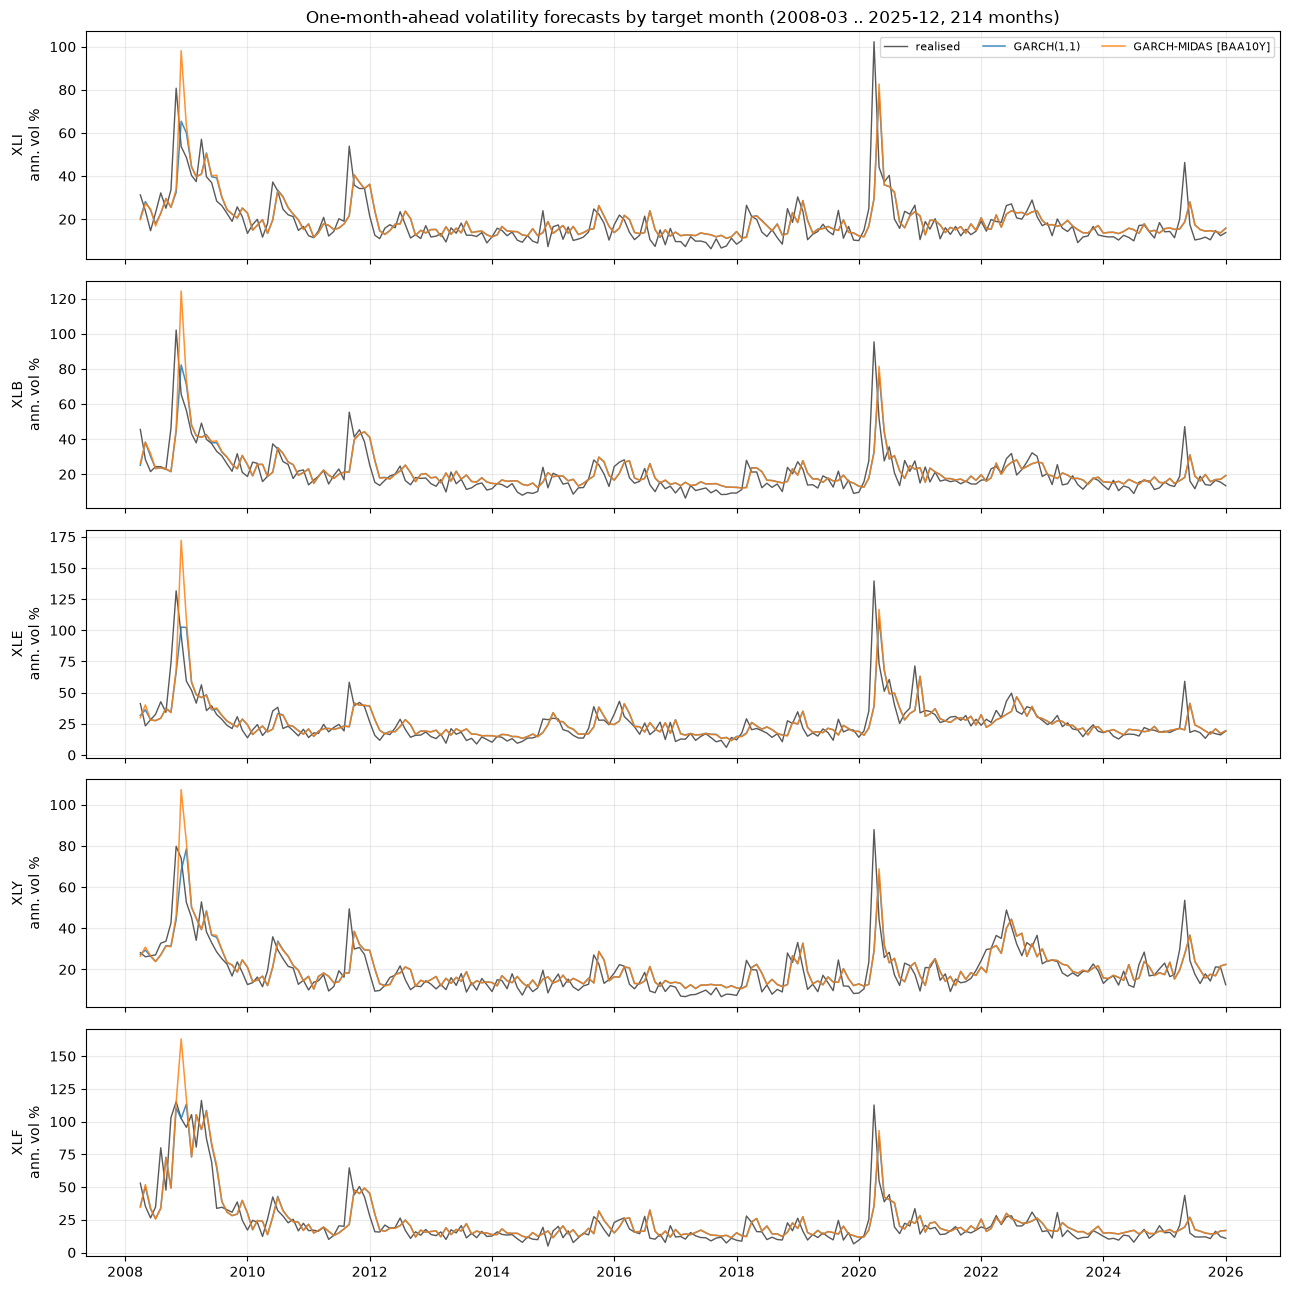

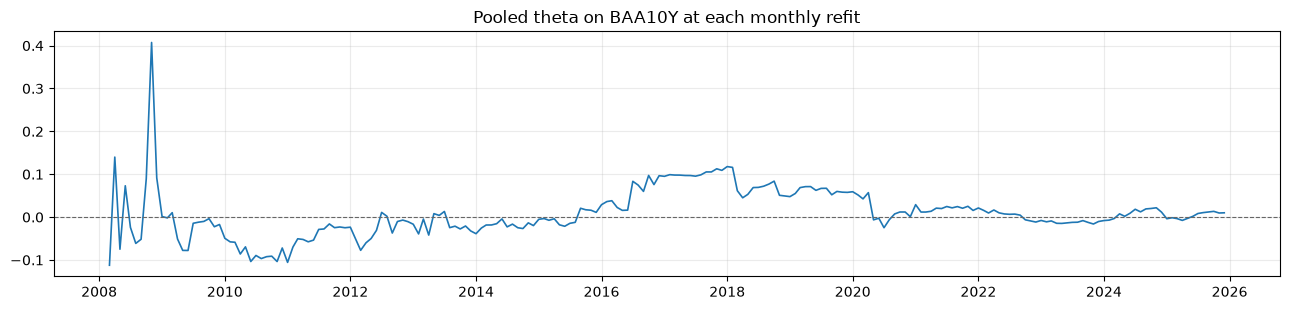

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(TICKERS), 1, figsize=(13, 13), sharex=True)
for ax, tk in zip(axes, TICKERS):
    g = detail[(detail.model == "garch") & (detail.etf == tk)]
    m = detail[(detail.model == MIDAS_LABEL) & (detail.etf == tk)]
    t = [p.to_timestamp(how="end") for p in g.target]
    ax.plot(t, np.sqrt(12 * g.actual_RV) * 100, color="0.35", lw=1.0, label="realised")
    ax.plot(t, np.sqrt(12 * g.rv2_hat) * 100, lw=1.1, alpha=0.85, label="GARCH(1,1)")
    ax.plot(t, np.sqrt(12 * m.rv2_hat) * 100, lw=1.1, alpha=0.85, label=f"GARCH-MIDAS [{DRIVER}]")
    ax.set_ylabel(f"{tk}\nann. vol %")
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8, ncol=3, loc="upper right")
axes[0].set_title(f"One-month-ahead volatility forecasts by target month "
                  f"({TARGETS[0]} .. {TARGETS[-1]}, {len(TARGETS)} months)")
fig.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(13, 3.2))
_r = REF[MIDAS_LABEL]
ax2.plot(pd.PeriodIndex(_r.origin, freq="M").to_timestamp(how="end"), _r.theta, lw=1.2)
ax2.axhline(0, color="0.4", lw=0.8, ls="--")
ax2.set_title(f"Pooled theta on {DRIVER} at each monthly refit")
ax2.grid(alpha=0.25)
fig2.tight_layout()
plt.show()

## Step 13: Robustness check: annual re-estimation

This robustness exercise evaluates whether the conclusion is sensitive to an annual rather
than monthly re-estimation schedule.

Parameters are re-estimated each February from 2008 to 2025 (18 refits) using only data
available at that date. Between refits, parameters are held fixed while forecasts continue
to condition on daily returns available at each month-end.

The code prints the parameters at each yearly refit, and checks that every parameter of
every ETF changes at every refit, to prove they are really re-estimated. Each model is
compared with GARCH on the same refit schedule.

The yearly-refit forecasts are saved in the Elastic Net's exact format to
`garch_forecasts_yearly_refit_tidy.csv`, with model names `garch_yearly_refit` and
`garch_midas_baa10y_yearly_refit`. The code checks that every row and every actual value
line up with the Elastic Net's file. It also checks that, at each refit date, the yearly
forecast equals the monthly forecast exactly, because the parameters there are the same.

In [15]:
"""Robustness: refit once a year instead of every month.

A fit at origin T uses only data up to T and does not depend on any other fit, so the
yearly-refit parameters are exactly the monthly fits made at the yearly refit dates. Between
refits the parameters are held fixed, while each forecast still uses all returns observed up
to its own origin (the filter runs through the latest data), as in the EN's midterm design.
"""
YEARLY_REFITS = [o for o in ORIGINS if (o - FIRST_ORIGIN) % 12 == 0]


def refit_origin_yearly(origin):
    return FIRST_ORIGIN + 12 * ((origin - FIRST_ORIGIN) // 12)


def yearly_forecasts(label):
    use_theta = MODELS[label] is not None
    x_np = macro_matrix[MODELS[label]].to_numpy(float) if use_theta else np.zeros(N_MONTHS)
    rows = []
    for origin in ORIGINS:
        r = refit_origin_yearly(origin)
        assert r <= origin, "parameters from the future"
        model = PooledGarchMidas(K_MIDAS, TICKERS, use_theta=use_theta).set_params(PAR[label][r])
        lo, hi = slice_bounds(K_MIDAS, origin + 1)
        for k, tk in enumerate(TICKERS):
            nd = estimate_sessions(origin + 1, OBS[k])
            f = model.forecast_h1(tk, RETS, MIDS, lo[k], hi[k], x_np[:origin + 1], origin, nd)
            a = float(rv2.loc[GRID[origin + 1], tk])
            rows.append(dict(model=label, etf=tk, origin=origin, refit_at=r, fc_level=f, actual_RV=a))
    d = pd.DataFrame(rows)
    d["qlike"] = qlike(d.actual_RV, d.fc_level)
    d["sq_err_log"] = (np.log(d.actual_RV) - np.log(d.fc_level)) ** 2
    return d


YR = {lab: yearly_forecasts(lab) for lab in MODELS}
for lab, d in YR.items():
    assert len(d) == len(ORIGINS) * len(TICKERS) and np.isfinite(d.fc_level).all() and (d.fc_level > 0).all()

# ---- proof that the parameters are re-estimated at every yearly refit ----
print(f"yearly refits: {len(YEARLY_REFITS)}, at {GRID[YEARLY_REFITS[0]]}, {GRID[YEARLY_REFITS[1]]}, ..., "
      f"{GRID[YEARLY_REFITS[-1]]}")
_rows = []
for r in YEARLY_REFITS:
    p = PAR[MIDAS_LABEL][r]
    t = p["per_ticker"]["XLI"]
    _rows.append(dict(refit=str(GRID[r]), theta=p["theta"], XLI_alpha=t["alpha"], XLI_beta=t["beta"], XLI_m=t["m"]))
print(f"\nGARCH-MIDAS[{DRIVER}] parameters at each yearly refit (XLI shown; all ETFs checked below)")
print(pd.DataFrame(_rows).to_string(index=False, formatters={
    "theta": "{:+.4f}".format, "XLI_alpha": "{:.5f}".format, "XLI_beta": "{:.5f}".format, "XLI_m": "{:.4f}".format}))
_changed = all(PAR[lab][a]["per_ticker"][tk][key] != PAR[lab][b]["per_ticker"][tk][key]
               for lab in MODELS for a, b in zip(YEARLY_REFITS[:-1], YEARLY_REFITS[1:])
               for tk in TICKERS for key in ["mu", "alpha", "beta", "m"])
_held = all(d.groupby("refit_at").origin.agg(lambda s: s.max() - s.min()).le(11).all() for d in YR.values())
print(f"\n[{'OK' if _changed else 'FAIL'}] every parameter of every ETF changes at every yearly refit (both models)")
print(f"[{'OK' if _held else 'FAIL'}] parameters are held for at most 12 months between refits")
assert _changed and _held
YEARLY_PARAMS_CHANGE = _changed

# ---- scores: each model against GARCH with the same refit schedule ----
_out = []
for loss, name in [("qlike", "QLIKE"), ("sq_err_log", "MSE log RV")]:
    g, m = YR["garch"], YR[MIDAS_LABEL]
    for lab, d in [("garch", g), (MIDAS_LABEL, m)]:
        row = {"loss": name, "model": lab}
        row.update({tk: d[d.etf == tk][loss].mean() for tk in TICKERS})
        row["pooled"] = d[loss].mean()
        _out.append(row)
YEARLY_T = pd.DataFrame(_out).set_index(["loss", "model"])
print("\nYEARLY refit: loss by ETF (lower is better)")
print(YEARLY_T.round(5).to_string())
_pct = pd.DataFrame({name: (YEARLY_T.loc[(name, MIDAS_LABEL)] / YEARLY_T.loc[(name, "garch")] - 1) * 100
                     for name in ["QLIKE", "MSE log RV"]}).T
print(f"\nYEARLY refit: GARCH-MIDAS[{DRIVER}] vs GARCH, % change in loss (negative = GARCH-MIDAS better)")
print(_pct.round(2).to_string())
_dm = []
for loss, name in [("qlike", "QLIKE"), ("sq_err_log", "MSE log RV")]:
    a = YR[MIDAS_LABEL].pivot(index="origin", columns="etf", values=loss)
    b = YR["garch"].pivot(index="origin", columns="etf", values=loss)
    md_, st, p, lg = diebold_mariano((a - b).mean(axis=1))
    _dm.append(dict(loss=name, mean_diff=md_, DM_stat=st, p_value=p, HAC_lags=lg,
                    months_MIDAS_better=float(((a - b).mean(axis=1) < 0).mean())))
print("\nYEARLY refit: Diebold-Mariano (loss differential averaged across ETFs per month)")
print(pd.DataFrame(_dm).set_index("loss").round(4).to_string())

# ---- monthly vs yearly, side by side ----
print("\nPooled QLIKE, monthly vs yearly refit")
print(pd.DataFrame({"monthly": QL_T["pooled"], "yearly": YEARLY_T.loc["QLIKE"]["pooled"]}).round(5).to_string())
YEARLY_T.to_csv("garch_phase2_scores_yearly_refit.csv")
print("\nsaved garch_phase2_scores_yearly_refit.csv")

# ---- yearly-refit forecasts in the Elastic Net's exact format ----
# At each yearly refit date the parameters ARE that month's monthly fit, so the forecast must
# equal the monthly-refit forecast exactly.
for lab in MODELS:
    y = YR[lab][YR[lab].origin == YR[lab].refit_at].copy()
    y["origin"] = [GRID[o] for o in y.origin]
    mth = detail[detail.model == lab].set_index(["etf", "origin"]).rv2_hat
    assert all(f == mth[(e, o)] for e, o, f in zip(y.etf, y.origin, y.fc_level)), f"{lab}: refit-month mismatch"
print("[OK] at all 18 yearly refit dates, the yearly forecasts equal the monthly-refit forecasts exactly")
_yt = []
for lab in MODELS:
    d = YR[lab].copy()
    d["model"] = lab + "_yearly_refit"
    d["date"] = [GRID[o].to_timestamp(how="end").strftime("%Y-%m-%d") for o in d.origin]
    d["actual_logRV"] = np.log(d.actual_RV)
    d["fc_log"] = np.log(d.fc_level)
    d["sigma2"] = np.nan
    d["etf"] = pd.Categorical(d.etf, TICKERS, ordered=True)
    _yt.append(d.sort_values(["etf", "origin"])[EN_COLS])
YEARLY_TIDY = pd.concat(_yt, ignore_index=True)
YEARLY_TIDY["etf"] = YEARLY_TIDY["etf"].astype(str)
for lab in YEARLY_TIDY.model.unique():
    for em in en.model.unique():
        a = YEARLY_TIDY[YEARLY_TIDY.model == lab].set_index(["etf", "date"]).sort_index()
        b = en[en.model == em].set_index(["etf", "date"]).sort_index()
        assert list(a.index) == list(b.index), f"{lab} vs {em}: (etf, date) keys differ"
        assert np.allclose(a.actual_RV, b.actual_RV, rtol=1e-10, atol=0), f"{lab} vs {em}: actual_RV"
        assert np.allclose(a.actual_logRV, b.actual_logRV, rtol=0, atol=1e-10), f"{lab} vs {em}: actual_logRV"
YEARLY_EN_MATCH = True
OUT_YEARLY_TIDY = os.path.join(PROJECT_ROOT, "garch_forecasts_yearly_refit_tidy.csv")
YEARLY_TIDY.to_csv(OUT_YEARLY_TIDY, index=False)
_chk = pd.read_csv(OUT_YEARLY_TIDY)
assert list(_chk.columns) == EN_COLS and len(_chk) == len(YEARLY_TIDY)
assert np.allclose(_chk.fc_level, YEARLY_TIDY.fc_level.to_numpy(), rtol=1e-12)
print(f"[OK] yearly-refit keys and actuals identical to every EN model ({list(en.model.unique())})")
print(f"saved {OUT_YEARLY_TIDY}  (EN format, {len(_chk)} rows = {len(MODELS)} models x {len(TICKERS)} ETFs x {len(ORIGINS)} months)")

yearly refits: 18, at 2008-02, 2009-02, ..., 2025-02

GARCH-MIDAS[BAA10Y] parameters at each yearly refit (XLI shown; all ETFs checked below)
  refit   theta XLI_alpha XLI_beta   XLI_m
2008-02 -0.1123   0.05271  0.94578 -8.1208
2009-02 +0.0103   0.06182  0.93529 -8.3249
2010-02 -0.0587   0.06354  0.93351 -8.3427
2011-02 -0.0506   0.07287  0.92249 -8.4291
2012-02 -0.0775   0.08541  0.90911 -8.3720
2013-02 -0.0045   0.08316  0.90902 -8.5477
2014-02 -0.0185   0.08063  0.91003 -8.6802
2015-02 -0.0074   0.08570  0.90265 -8.7711
2016-02 +0.0382   0.08689  0.89939 -8.8055
2017-02 +0.0980   0.08961  0.88969 -8.9417
2018-02 +0.0615   0.09460  0.88631 -8.9358
2019-02 +0.0688   0.09521  0.88472 -8.9387
2020-02 +0.0425   0.09420  0.88622 -8.9193
2021-02 +0.0118   0.10347  0.87734 -8.8346
2022-02 +0.0095   0.10386  0.87514 -8.8636
2023-02 -0.0090   0.10006  0.88121 -8.8290
2024-02 -0.0033   0.09758  0.88314 -8.8694
2025-02 -0.0035   0.09619  0.88346 -8.8998

[OK] every parameter of every ETF change

[OK] yearly-refit keys and actuals identical to every EN model (['en_full_macro', 'en_no_vix', 'en_no_macro'])
saved .\garch_forecasts_yearly_refit_tidy.csv  (EN format, 2140 rows = 2 models x 5 ETFs x 214 months)


## Step 13b: Robustness check: ETF-specific credit-spread effects

The primary model imposes a common `theta`. This extension relaxes that restriction by
estimating ETF-specific credit-spread coefficients under both monthly and annual refits.

**How it is fitted.** With no parameter shared, the model is exactly five single-ETF
GARCH-MIDAS fits. Each one uses the same careful recipe as the main fits:
* 14 starting points, each climbed to its top, keeping the highest;
* that ETF's GARCH answer with `theta = 0` as one start, so each ETF fits at least as well as
  its GARCH;
* a convergence check on every fit.

**Refit schedules.** It is refitted every month (214 × 5 fits). The yearly version uses the
February fits, held for 12 months, exactly as in Step 13.

**What the code checks:**
* every fit converged;
* every ETF fits at least as well as its own GARCH;
* parameters change every month;
* both forecast sets match the Elastic Net's rows and actual values.

They are saved in the Elastic Net's format to `garch_midas_own_theta_forecasts_tidy.csv`
(models `garch_midas_baa10y_own_theta` and `garch_midas_baa10y_own_theta_yearly_refit`).

In [16]:
"""GARCH-MIDAS with a SEPARATE theta for each ETF, monthly and yearly refit.

With no parameter shared across ETFs, the model is exactly five single-ETF GARCH-MIDAS fits.
Each uses the same recipe as the main fits: 3 fixed + 10 seeded random starts + that ETF's
GARCH answer at theta = 0 (so nesting holds per ETF), every start climbed to its top, and a
convergence certificate on every fit. Fits are saved in cache_gm_phase2/ like the others.
"""
OWN_LABEL = MIDAS_LABEL + "_sector_theta"
_x = macro_matrix[DRIVER].to_numpy(float)


def own_tag(tk, origin):
    return f"{spec_for(OWN_LABEL, True)}|etf={tk}|origin={origin}"


def fit_own(tk, origin, x_np, rets, garch_params):
    k = TICKERS.index(tk)
    n_obs = origin + 1
    lo, hi = slice_bounds(K_MIDAS, n_obs)
    m = PooledGarchMidas(K_MIDAS, [tk], use_theta=True, n_starts=N_STARTS,
                         seed=100_000 + 1_000 * (k + 1) + origin, n_random=N_RANDOM)
    nested = dict(per_ticker={tk: garch_params["per_ticker"][tk]}, theta=0.0, omega2=garch_params["omega2"])
    m.fit(rets, MIDS, lo[k:k + 1].copy(), hi[k:k + 1].copy(), x_np[:n_obs], n_obs,
          extra_z0=[m.params_to_z(nested, theta=0.0)])
    return m


def etf_garch_loglik(tk, origin):
    """That ETF's share of the pooled GARCH log-likelihood (GARCH shares no parameter across ETFs)."""
    k = TICKERS.index(tk)
    lo, hi = slice_bounds(K_MIDAS, origin + 1)
    g = PooledGarchMidas(K_MIDAS, [tk], use_theta=False)
    z = g.params_to_z(dict(per_ticker={tk: PAR["garch"][origin]["per_ticker"][tk]}, theta=0.0, omega2=OMEGA2_FIXED_K1))
    return -nll_pooled(z, RETS, MIDS, lo[k:k + 1].copy(), hi[k:k + 1].copy(), np.zeros(origin + 1), K_MIDAS, origin + 1, 1, 0)


OWN_PAR, _own_log = {}, []
_t0 = time.time()
for origin in ORIGINS:
    for tk in TICKERS:
        hit = cache_get(own_tag(tk, origin))
        if hit is None:
            m = fit_own(tk, origin, _x, RETS, PAR["garch"][origin])
            hit = dict(params=m.params, fit_ok=bool(m.fit_ok),
                       loglik=float(m.loglik) if np.isfinite(m.loglik) else None, conv_gap=float(m.conv_gap))
            cache_put(own_tag(tk, origin), hit)
        OWN_PAR[(tk, origin)] = hit["params"]
        _own_log.append(dict(etf=tk, origin=origin, fit_ok=hit["fit_ok"], conv_gap=hit["conv_gap"],
                             gain=hit["loglik"] - etf_garch_loglik(tk, origin), theta=hit["params"]["theta"]))
OWN_LOG = pd.DataFrame(_own_log)
_unchanged = sum(OWN_PAR[(tk, a)] == OWN_PAR[(tk, b)] for tk in TICKERS for a, b in zip(ORIGINS[:-1], ORIGINS[1:]))
print(f"{len(OWN_LOG)} single-ETF fits ({time.time() - _t0:.0f}s): converged {int(OWN_LOG.fit_ok.sum())}, "
      f"largest further gain from a second climb {OWN_LOG.conv_gap.max():.1e}")
print(f"loglik gain over that ETF's GARCH fit: min {OWN_LOG.gain.min():+.4f} (nesting needs >= 0), median {OWN_LOG.gain.median():+.3f}")
print(f"month-to-month refits with identical parameters: {_unchanged}")
assert OWN_LOG.fit_ok.all() and OWN_LOG.conv_gap.max() < 1e-6 and OWN_LOG.gain.min() >= -1e-6 and _unchanged == 0
OWN_FITS_OK = True

print("\ntheta by ETF across the 214 monthly fits")
for tk in TICKERS:
    th = OWN_LOG[OWN_LOG.etf == tk].theta
    print(f"  {tk}: mean {th.mean():+.3f}, positive in {(th > 0).mean():.0%} of months")


# ---- forecasts: monthly refit, and yearly refit (parameters from the latest February fit) ----
def own_forecasts(every):
    rows = []
    for origin in ORIGINS:
        r = FIRST_ORIGIN + every * ((origin - FIRST_ORIGIN) // every)
        lo, hi = slice_bounds(K_MIDAS, origin + 1)
        for k, tk in enumerate(TICKERS):
            mdl = PooledGarchMidas(K_MIDAS, [tk], use_theta=True).set_params(OWN_PAR[(tk, r)])
            nd = estimate_sessions(origin + 1, OBS[k])
            f = mdl.forecast_h1(tk, RETS, MIDS, lo[k], hi[k], _x[:origin + 1], origin, nd)
            rows.append(dict(etf=tk, origin=origin, fc_level=f, actual_RV=float(rv2.loc[GRID[origin + 1], tk])))
    d = pd.DataFrame(rows)
    assert len(d) == len(ORIGINS) * len(TICKERS) and np.isfinite(d.fc_level).all() and (d.fc_level > 0).all()
    d["qlike"] = qlike(d.actual_RV, d.fc_level)
    d["sq_err_log"] = (np.log(d.actual_RV) - np.log(d.fc_level)) ** 2
    return d


OWN_M, OWN_Y = own_forecasts(1), own_forecasts(12)
_gm = detail[detail.model == "garch"][["etf", "origin", "rv2_hat", "actual_RV"]].copy()
_gm["origin"] = [int(GRID.get_loc(o)) for o in _gm.origin]
_gm["qlike"] = qlike(_gm.actual_RV, _gm.rv2_hat)
_gm["sq_err_log"] = (np.log(_gm.actual_RV) - np.log(_gm.rv2_hat)) ** 2
OWN_PCT = {}
for name, own, gar in [("MONTHLY refit", OWN_M, _gm), ("YEARLY refit", OWN_Y, YR["garch"])]:
    print(f"\n{name}: GARCH-MIDAS[{DRIVER}] with a separate theta per ETF vs GARCH (same refit schedule)")
    tab = {}
    for loss, ln in [("qlike", "QLIKE"), ("sq_err_log", "MSE log RV")]:
        a_ = own.pivot(index="origin", columns="etf", values=loss)[TICKERS]
        b_ = gar.pivot(index="origin", columns="etf", values=loss)[TICKERS]
        row = {tk: (a_[tk].mean() / b_[tk].mean() - 1) * 100 for tk in TICKERS}
        row["pooled"] = (a_.values.mean() / b_.values.mean() - 1) * 100
        tab[f"{ln} % change"] = row
        tab[f"{ln} DM p"] = {**{tk: diebold_mariano(a_[tk] - b_[tk])[2] for tk in TICKERS},
                             "pooled": diebold_mariano((a_ - b_).mean(axis=1))[2]}
    OWN_PCT[name] = pd.DataFrame(tab).T
    print(OWN_PCT[name].round(3).to_string())
    _wins = [tk for tk in TICKERS if OWN_PCT[name].loc["QLIKE % change", tk] < 0]
    print(f"ETFs where GARCH-MIDAS beats GARCH on QLIKE: {_wins or 'none'}")

# ---- save both in the Elastic Net's exact format, and check it ----
_parts = []
for d, lab in [(OWN_M, MIDAS_LABEL + "_own_theta"), (OWN_Y, MIDAS_LABEL + "_own_theta_yearly_refit")]:
    t = d.copy()
    t["model"] = lab
    t["date"] = [GRID[o].to_timestamp(how="end").strftime("%Y-%m-%d") for o in t.origin]
    t["actual_logRV"] = np.log(t.actual_RV)
    t["fc_log"] = np.log(t.fc_level)
    t["sigma2"] = np.nan
    t["etf"] = pd.Categorical(t.etf, TICKERS, ordered=True)
    _parts.append(t.sort_values(["etf", "origin"])[EN_COLS])
OWN_TIDY = pd.concat(_parts, ignore_index=True)
OWN_TIDY["etf"] = OWN_TIDY["etf"].astype(str)
for lab in OWN_TIDY.model.unique():
    for em in en.model.unique():
        a = OWN_TIDY[OWN_TIDY.model == lab].set_index(["etf", "date"]).sort_index()
        b = en[en.model == em].set_index(["etf", "date"]).sort_index()
        assert list(a.index) == list(b.index), f"{lab} vs {em}: (etf, date) keys differ"
        assert np.allclose(a.actual_RV, b.actual_RV, rtol=1e-10, atol=0), f"{lab} vs {em}: actual_RV"
OWN_EN_MATCH = True
OUT_OWN = os.path.join(PROJECT_ROOT, "garch_midas_own_theta_forecasts_tidy.csv")
OWN_TIDY.to_csv(OUT_OWN, index=False)
_chk = pd.read_csv(OUT_OWN, float_precision="round_trip")
assert list(_chk.columns) == EN_COLS and len(_chk) == len(OWN_TIDY) and (_chk.fc_level.values == OWN_TIDY.fc_level.values).all()
print(f"\n[OK] keys and actuals identical to every EN model; saved {OUT_OWN} ({len(_chk)} rows)")

1070 single-ETF fits (1s): converged 1070, largest further gain from a second climb 4.7e-11
loglik gain over that ETF's GARCH fit: min +0.0000 (nesting needs >= 0), median +0.762
month-to-month refits with identical parameters: 0

theta by ETF across the 214 monthly fits
  XLI: mean +0.346, positive in 100% of months
  XLB: mean +0.140, positive in 100% of months
  XLE: mean -0.304, positive in 0% of months
  XLY: mean +0.127, positive in 89% of months
  XLF: mean +0.011, positive in 55% of months



MONTHLY refit: GARCH-MIDAS[BAA10Y] with a separate theta per ETF vs GARCH (same refit schedule)
                       XLI    XLB    XLE    XLY    XLF  pooled
QLIKE % change       2.658 -1.254  3.454  1.866  1.946   1.778
QLIKE DM p           0.412  0.571  0.197  0.175  0.105   0.082
MSE log RV % change  3.438  1.448  2.557  1.876  0.601   1.911
MSE log RV DM p      0.406  0.452  0.174  0.330  0.506   0.235
ETFs where GARCH-MIDAS beats GARCH on QLIKE: ['XLB']

YEARLY refit: GARCH-MIDAS[BAA10Y] with a separate theta per ETF vs GARCH (same refit schedule)
                       XLI    XLB    XLE    XLY    XLF  pooled
QLIKE % change       2.598 -1.493  4.658  1.920  2.776   2.155
QLIKE DM p           0.351  0.445  0.241  0.152  0.211   0.067
MSE log RV % change  0.362  0.366  2.719  1.178  1.157   1.143
MSE log RV DM p      0.892  0.766  0.300  0.383  0.437   0.284
ETFs where GARCH-MIDAS beats GARCH on QLIKE: ['XLB']



[OK] keys and actuals identical to every EN model; saved .\garch_midas_own_theta_forecasts_tidy.csv (2140 rows)


## Step 14: Diagnostic analysis of GARCH-MIDAS forecast errors

The following diagnostics examine whether extrapolation of the credit spread contributes to
the out-of-sample performance of GARCH-MIDAS.

1. **The October 2008 forecast.** At the end of October 2008 the credit spread jumped far
   beyond anything in the 2003–2008 estimation window. The model's long-run part depends
   on the spread through an exponential, so this value was extrapolated far outside the
   range the model had been fitted on.
2. **Holding the input inside its fitted range.** As a diagnostic, each forecast is
   recomputed with the spread capped at the highest (and lowest) value seen in that
   month's estimation window. If extrapolation is the problem, the loss should shrink.

In [17]:
"""Why GARCH-MIDAS loses: two measured diagnoses."""
_x = macro_matrix[DRIVER].to_numpy(float)

# ---------------- 1. the October 2008 forecast ----------------
_o = int(GRID.get_loc(pd.Period("2008-10", "M")))
_p = PAR[MIDAS_LABEL][_o]
_z_used = (_x[_o] - _p["x_mean"]) / _p["x_std"]                     # the value the forecast uses
_z_fit = (_x[:_o] - _p["x_mean"]) / _p["x_std"]                    # values the fit was estimated on
print(f"1. The forecast made at the end of {GRID[_o]} for {GRID[_o + 1]}")
print(f"   theta estimated at that date: {_p['theta']:+.3f}")
print(f"   {DRIVER} in {GRID[_o]}: {_x[_o]:.2f}  = {_z_used:+.1f} standard deviations from its estimation-window mean")
print(f"   largest value the fit had seen: {_z_fit.max():+.1f} standard deviations ({GRID[int(np.argmax(_z_fit))]})")
_g = detail[(detail.model == "garch") & (detail.origin == GRID[_o])].set_index("etf")
_m = detail[(detail.model == MIDAS_LABEL) & (detail.origin == GRID[_o])].set_index("etf")
print("   forecasts for the next month (annualised volatility, %):")
for tk in TICKERS:
    print(f"     {tk}: GARCH {np.sqrt(12 * _g.rv2_hat[tk]) * 100:5.1f}   GARCH-MIDAS {np.sqrt(12 * _m.rv2_hat[tk]) * 100:5.1f}"
          f"   realised {np.sqrt(12 * _g.actual_RV[tk]) * 100:5.1f}   (variance ratio MIDAS/GARCH {_m.rv2_hat[tk] / _g.rv2_hat[tk]:.2f})")
_d = (SCORED[SCORED.model == MIDAS_LABEL].set_index(["date", "etf"]).qlike
      - SCORED[SCORED.model == "garch"].set_index(["date", "etf"]).qlike).groupby(level="date").sum()
_key = GRID[_o].to_timestamp(how="end").strftime("%Y-%m-%d")
OCT08_SHARE = float(_d[_key] / _d.sum())
print(f"   this single month accounts for {OCT08_SHARE:.0%} of GARCH-MIDAS's total QLIKE shortfall over 214 months")

# ---------------- 2. holding the macro input inside its fitted range ----------------
_rows = []
_binding = []
for origin in ORIGINS:
    p = PAR[MIDAS_LABEL][origin]
    zs = (_x[:origin + 1] - p["x_mean"]) / p["x_std"]
    z_in = zs[K_MIDAS - 1:origin]                    # K = 1: months 0 .. origin-1 feed the fitted tau
    if zs[origin] > z_in.max() or zs[origin] < z_in.min():
        _binding.append(origin)
    model = PooledGarchMidas(K_MIDAS, TICKERS, use_theta=True, cap_macro=True).set_params(p)
    lo, hi = slice_bounds(K_MIDAS, origin + 1)
    for k, tk in enumerate(TICKERS):
        nd = estimate_sessions(origin + 1, OBS[k])
        _rows.append(dict(etf=tk, origin=GRID[origin], fc=model.forecast_h1(tk, RETS, MIDS, lo[k], hi[k],
                                                                            _x[:origin + 1], origin, nd)))
CAP = pd.DataFrame(_rows).merge(detail[detail.model == MIDAS_LABEL][["etf", "origin", "rv2_hat", "actual_RV"]],
                                on=["etf", "origin"])
_diff_months = sorted({int(GRID.get_loc(o)) for o in CAP[CAP.fc != CAP.rv2_hat].origin})
assert _diff_months == _binding, "the cap changed a forecast in a month where it should not bind"
CAP["qlike"] = qlike(CAP.actual_RV, CAP.fc)
CAP["sq_err_log"] = (np.log(CAP.actual_RV) - np.log(CAP.fc)) ** 2
print(f"\n2. Holding the {DRIVER} input inside the range seen in each estimation window")
print(f"   the cap changes the forecast in {len(_binding)} of {len(ORIGINS)} months: "
      f"{', '.join(str(GRID[o]) for o in _binding)}")
_cap_pct = {}
for loss, name in [("qlike", "QLIKE"), ("sq_err_log", "MSE log RV")]:
    g = SCORED[SCORED.model == "garch"]
    r = {tk: (CAP[CAP.etf == tk][loss].mean() / g[g.etf == tk][loss].mean() - 1) * 100 for tk in TICKERS}
    r["pooled"] = (CAP[loss].mean() / g[loss].mean() - 1) * 100
    _cap_pct[name] = r
CAP_PCT = pd.DataFrame(_cap_pct).T
print("   % change in loss vs GARCH, with the cap (main result without the cap is in Step 10):")
print(CAP_PCT.round(2).to_string())

1. The forecast made at the end of 2008-10 for 2008-11
   theta estimated at that date: +0.407
   BAA10Y in 2008-10: 5.56  = +4.8 standard deviations from its estimation-window mean
   largest value the fit had seen: +2.4 standard deviations (2008-09)
   forecasts for the next month (annualised volatility, %):
     XLI: GARCH  65.4   GARCH-MIDAS  98.1   realised  53.7   (variance ratio MIDAS/GARCH 2.25)
     XLB: GARCH  82.3   GARCH-MIDAS 124.4   realised  65.5   (variance ratio MIDAS/GARCH 2.29)
     XLE: GARCH 102.6   GARCH-MIDAS 172.2   realised  95.9   (variance ratio MIDAS/GARCH 2.82)
     XLY: GARCH  68.0   GARCH-MIDAS 107.3   realised  74.0   (variance ratio MIDAS/GARCH 2.49)
     XLF: GARCH 102.5   GARCH-MIDAS 163.1   realised 102.4   (variance ratio MIDAS/GARCH 2.53)
   this single month accounts for 60% of GARCH-MIDAS's total QLIKE shortfall over 214 months



2. Holding the BAA10Y input inside the range seen in each estimation window
   the cap changes the forecast in 9 of 214 months: 2008-03, 2008-09, 2008-10, 2008-11, 2024-02, 2024-03, 2024-04, 2024-11, 2024-12


   % change in loss vs GARCH, with the cap (main result without the cap is in Step 10):
             XLI   XLB   XLE   XLY   XLF  pooled
QLIKE       0.84  0.35  0.93  0.76  0.59    0.70
MSE log RV  0.58  0.19  0.90  0.34  0.47    0.49


### Additional macroeconomic drivers

Additional economically motivated macroeconomic variables are evaluated using the same
monthly-refit protocol, implementation checks and GARCH benchmark. The summary below
reports the relevant out-of-sample and in-sample evidence.

The table reports the QLIKE change relative to GARCH (negative values favour GARCH-MIDAS),
together with in-sample coefficient evidence:

| Variable | XLI | XLB | All 5 | `theta` > 0 in | Median gain in log-likelihood |
|---|---|---|---|---|---|
| BAA10Y (credit spread) | +1.09% | +0.85% | +1.12% | 51% of months | 0.05 |
| UNRATE (unemployment) | +1.45% | −1.18% | +1.39% | 96% | 8.79 |
| CPIAUCSL (inflation) | +2.45% | +2.07% | +1.55% | 57% | 0.09 |
| DGS3MO (3-month T-bill rate) | +1.60% | +0.91% | +1.06% | 21% | 0.20 |
| INDPRO (industrial production) | +0.96% | +1.27% | +0.70% | 91% | 1.83 |
| UMCSENT (consumer sentiment) | +4.43% | +2.07% | +2.47% | 0.5% | 5.81 |
| T10Y2Y (yield-curve slope) | +1.53% | +0.48% | +1.02% | 85% | 1.40 |
| T5YIE (expected inflation) | +5.06% | +4.08% | +3.11% | 99.5% | 1.30 |
| T5YIE − T10YIE | +3.81% | +3.69% | +2.47% | 91% | 0.41 |

**Excluded variables:**
* VIX, because it is itself a volatility forecast.
* Oil and the euro exchange rate, because they have no clear channel to US sector
  volatility.
* Policy uncertainty (`USEPUINDXD`). It was tested, but its historical values are revised
  and the record of the original, unrevised values only starts in 2014. A backtest starting in 2008
  would therefore use information that was not available at the time, so it cannot be
  used.

**What the table shows:**

* **No variable beats GARCH overall.** The result is not specific to the credit spread.
* **The macro information is real in-sample.**
  * Unemployment raises the fit by a median of 8.8 log-likelihood points, with the expected
    positive sign in 96% of months: higher unemployment, higher volatility.
  * Consumer sentiment raises it by 5.8 points, with the expected negative sign in 99.5% of
    months: worse sentiment, higher volatility.
  * Twice the gain is far above 3.84, the value needed for one extra parameter to be
    statistically significant at 5%.
  * So these variables are clearly related to volatility; they just do not improve
    one-month-ahead forecasts.
* **Materials (XLB) is where macro comes closest.**
  * Across the 20 specifications tested (the nine variables above with one shared
    `theta`, the same nine with a separate `theta` for each ETF, and the yearly-refit
    credit spread with shared and with separate `theta`), XLB beats GARCH in four. Three of
    these are by more than 1%:
    * unemployment (−1.18%);
    * the credit spread with its own `theta`, refitted monthly (−1.25%);
    * the credit spread with its own `theta`, refitted yearly (−1.49%; Step 13b).
  * XLF beats GARCH in two, by less than 0.4%. Industrials, energy and consumer
    discretionary never do.
  * None of these sector gains is statistically significant (p between 0.44 and 0.57 for
    the three larger XLB cases), so this is a pattern, not a finding.

**A note on the midterm results.** The midterm comparison favoured GARCH-MIDAS. Its
estimation used an optimiser that stopped before reaching the best-fitting parameters, so
neither model was properly fitted. Phase 2 corrects this: every fit is checked to be at its
maximum (Step 5). With correct estimation the credit spread does not improve on GARCH,
under either monthly or yearly refits.

## Step 15: Conclusions and implications for subsequent models

1. **GARCH-MIDAS does not outperform GARCH at the one-month horizon.** This holds for the credit spread
   under monthly and yearly refits, and for every other economic variable tested.
2. **The macroeconomic variables contain in-sample information but do not improve this forecasting specification.**
   Unemployment and consumer sentiment have strong, correctly signed effects in-sample.
   Past returns, which GARCH already uses, carry most of what can be known about
   next month's volatility.
3. **The diagnostic evidence identifies potential limitations of the single-variable MIDAS specification.**

| What limits GARCH-MIDAS | Evidence from this notebook | What could address it |
|---|---|---|
| One variable enters linearly (in logs), so extreme values are extrapolated | Oct 2008: the forecast used a spread far outside its fitted range and over-forecast; capping the input reduces the loss (Step 14) | Non-linear models whose effects are bounded by the data seen, such as tree-based **XGBoost** |
| One variable at a time | Each variable carries some information in-sample, but none is enough alone (Step 14) | Models that combine many variables, such as the **Elastic Net** and XGBoost |
| The macro effect is noisy to estimate from monthly data | `theta` changes sign from month to month in the early years (Step 12 plot) | Regularisation, the core of the **Elastic Net** |
| Sectors may react differently | With a separate `theta` per ETF, XLB beats GARCH under both refits (Step 13b); XLI never does (Step 14) | A separate model for each ETF, as in the Elastic Net |

These motivate the Elastic Net and XGBoost stages; they do not show that those models will
succeed. Whether combining many macro variables, with regularisation or non-linearity,
improves on GARCH is the question those stages answer.

## How the professor's Phase 2 comments are addressed

| Comment | Where it is addressed |
|---|---|
| GARCH vs GARCH-MIDAS gives the parallel comparison inside the GARCH family | Both models use the same code, data, sample, refits and forecast dates. GARCH-MIDAS contains GARCH exactly, so the only difference is the economic variable (Steps 4, 5 and 8). |
| The monthly RV forecast should be the sum of the 1- to roughly 21-step-ahead daily variance forecasts | Built that way (Step 3), and checked two ways: an explicit day-by-day sum and a 400,000-month simulation (Step 6). |
| Exponentiating a log forecast is biased low; taking logs of a GARCH forecast is biased high; MSE on log RV mechanically penalises GARCH | GARCH forecasts the RV level directly, so no log-normal correction is needed and `sigma2` is left blank (Step 9). The Elastic Net applies its own correction to its log forecasts. Step 10 explains why MSE on log RV tilts against GARCH. |
| Report QLIKE on the RV level alongside MSE on log RV (Patton 2011) | Both losses, per ETF and pooled, with Diebold–Mariano tests, for the monthly refit (Step 10) and the yearly refit (Step 13). |
| Forecasts on a common basis with the other models | All three output files use the Elastic Net's exact columns, rows and actual values, checked in Steps 9, 13 and 13b. |
| Macro series are first-release values dated by publication | BAA10Y is market data: known at the time and never revised. Policy uncertainty was excluded because its historical values are revised (Step 14). |
| Per-ETF table: best forecast model and its gain vs GARCH | Monthly refit: GARCH is the better of our two models for every ETF on both losses (Step 10). Yearly refit: GARCH again, except XLB on QLIKE, where GARCH-MIDAS is better by 0.10% (Step 13). With a separate `theta` per ETF, GARCH-MIDAS is better for XLB on QLIKE under both refits (Step 13b). The portfolio half of the table is built in the portfolio stage. |
| Per-ETF managed portfolios with Sharpe, alpha, maximum drawdown and turnover; wording on c and k; XGBoost constraints and pooling; the HAR-style no-macro benchmark; the Elastic Net without VIX | Outside this notebook: these belong to the portfolio, XGBoost and Elastic Net stages. Portfolios should use `fc_level` from `garch_forecasts_expanding_tidy.csv`. |

## Step 16: Reproducibility checklist

All reported quantities are generated directly from the implemented backtest.

In [18]:
"""Every answer is computed from the objects the run actually used."""
_r = REF["garch"]
_est = _r.est_months.to_numpy(int)
_gaps = sorted({(GRID[REFIT_ORIGINS[i + 1]] - GRID[REFIT_ORIGINS[i]]).n
                for i in range(len(REFIT_ORIGINS) - 1)})
_h = {(t - o).n for f in FC.values() for o, t in zip(f.origin, f.target)}
_lo, _hi = slice_bounds(K_MIDAS, FIRST_ORIGIN + 1)
_last_used = int(MIDS[_lo[0]:_hi[0]].max())
_en = pd.read_csv(EN_TIDY_PATH)

checks = {
    "burn-in is 60 estimation months": FIRST_ORIGIN - K_MIDAS + 1 == BURN_IN == 60,
    "first estimation window 2003-03 .. 2008-02": (str(GRID[K_MIDAS]), str(GRID[FIRST_ORIGIN])) == ("2003-03", "2008-02"),
    "first forecast: origin 2008-02 -> target 2008-03": (str(GRID[FIRST_ORIGIN]), str(TARGETS[0])) == ("2008-02", "2008-03"),
    "last target 2025-12": str(TARGETS[-1]) == "2025-12",
    "214 forecasts per ETF per model": len(TARGETS) == 214,
    "refit every month (214 refits per model)": _gaps == [1] and len(_r) == 214,
    "expanding window (estimation months 60 .. 273, strictly increasing)":
        bool(np.all(np.diff(_est) == 1)) and _est[0] == 60 and _est[-1] == 273,
    "every forecast is exactly h = 1 month ahead": _h == {1},
    "every one of the 428 fits reached its maximum (second climb gains < 1e-6)": CONV_GAP_MAX < 1e-6,
    "parameters re-estimated every month (no two consecutive fits identical)": all(
        PAR[_l][REFIT_ORIGINS[i]] != PAR[_l][REFIT_ORIGINS[i + 1]]
        for _l in MODELS for i in range(len(REFIT_ORIGINS) - 1)),
    "yearly robustness: 18 refits, every parameter re-estimated at each one": len(YEARLY_REFITS) == 18 and YEARLY_PARAMS_CHANGE,
    "leakage audit bit-identical": AUDIT_WORST == 0.0,
    "estimation never reaches past the origin month": _last_used == FIRST_ORIGIN,
    "RV^2 built from excess returns (xret_*)": all(c.startswith("xret_") for c in RET_COLUMNS_USED),
    "January 2003 excluded": GRID[0] == pd.Period("2003-02", "M"),
    "output keys and actuals identical to EN": bool(globals().get("EN_MATCH", False)),
    "yearly-refit output keys and actuals identical to EN": bool(globals().get("YEARLY_EN_MATCH", False)),
    "separate-theta model: 1070 fits converged, nested per ETF, re-estimated every month": bool(globals().get("OWN_FITS_OK", False)),
    "separate-theta output keys and actuals identical to EN": bool(globals().get("OWN_EN_MATCH", False)),
    "same row count per model as EN": len(tidy) // len(MODELS) == len(_en) // _en.model.nunique(),
}
print("PROTOCOL CONFIRMATION")
print("=" * 80)
for k, v in checks.items():
    print(f"  [{'OK ' if v else 'FAIL'}] {k}")
print(f"\n  data files read as model inputs : {os.path.basename(PRICE_PATH)}, {os.path.basename(MACRO_PATH)}")
print(f"  read for verification only      : {os.path.basename(EN_TIDY_PATH)}")
assert all(checks.values()), "protocol confirmation failed"
print("\nALL PROTOCOL CHECKS PASS")

PROTOCOL CONFIRMATION
  [OK ] burn-in is 60 estimation months
  [OK ] first estimation window 2003-03 .. 2008-02
  [OK ] first forecast: origin 2008-02 -> target 2008-03
  [OK ] last target 2025-12
  [OK ] 214 forecasts per ETF per model
  [OK ] refit every month (214 refits per model)
  [OK ] expanding window (estimation months 60 .. 273, strictly increasing)
  [OK ] every forecast is exactly h = 1 month ahead
  [OK ] every one of the 428 fits reached its maximum (second climb gains < 1e-6)
  [OK ] parameters re-estimated every month (no two consecutive fits identical)
  [OK ] yearly robustness: 18 refits, every parameter re-estimated at each one
  [OK ] leakage audit bit-identical
  [OK ] estimation never reaches past the origin month
  [OK ] RV^2 built from excess returns (xret_*)
  [OK ] January 2003 excluded
  [OK ] output keys and actuals identical to EN
  [OK ] yearly-refit output keys and actuals identical to EN
  [OK ] separate-theta model: 1070 fits converged, nested per ETF,

## Integration notes

* **Joining with other models:** match rows on `etf` and `date`. Step 9 confirmed every row
  lines up with the Elastic Net file.
* **`sigma2` is blank on purpose** for the GARCH rows (see Step 9). Use `fc_level` directly.
* **Not built here:** the per-ETF volatility-managed portfolios (Sharpe ratio, alpha,
  maximum drawdown, turnover). They should use `fc_level` from
  `garch_forecasts_expanding_tidy.csv`.